# Ensemble i Global LightGBM

En l'avaluació, cap model individual no supera MASE=1 de forma consistent sobre totes les tecnologies i tots els folds. Dues estratègies complementàries poden millorar el rendiment sense incorporar dades externes:

**1. Ensemble (ETS Additiu + AutoSARIMA + TBATS).** La combinació simple (mitjana aritmètica) de les prediccions dels tres millors models estadístics del benchmark esmorteeix els errors individuals. La intuïció és directa: cada model comet errors en diferent direcció. L'ETS Additiu és estable però subestima els pics en sèries amb variança creixent. AutoSARIMA captura bé l'autocorrelació però pot ser rígid davant canvis de nivell. TBATS compensa via la transformació Box-Cox però és menys precís en sèries amb poca variança. La seva combinació, documentada com a millor pràctica a les competicions M (Makridakis et al., 2019), redueix l'error esperat sense requerir cap dada addicional ni cap reentrenament.

**2. Global LightGBM (cross-series).** El problema del LightGBM individual era l'escassetat de dades: N≈84 observacions per sèrie no és suficient per aprendre l'estacionalitat de forma implícita via gradient boosting. Si s'entrena un sol model sobre les 7 sèries simultàniament s'obtenen 7×84≈588 observacions d'entrenament — set vegades més. El model pot aprendre patrons compartits d'estacionalitat i tendència (tots els vehicles matriculats a Catalunya segueixen un cicle anual similar) i al mateix temps distingir les tecnologies via una variable `tech_id` categòrica (valors 0–6). Mantenem l'estratègia *direct multi-step*: un model independent per a cada horitzó h=1..12.

> **Prerequisit:** executar tots els notebooks de models anteriors (baseline.ipynb, sarima.ipynb, tbats.ipynb, lgbm.ipynb), ja que l'Ensemble carrega els seus CSV de resultats.

In [1]:
import sys
sys.path.insert(0, '../src')

import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import lightgbm as lgb
import time
import warnings
warnings.filterwarnings('ignore')
from pathlib import Path
from matplotlib.lines import Line2D

from features import TECNOLOGIES_MODELITZABLES, build_ml_features, get_feature_columns
from evaluation import compute_metrics, walk_forward_cv_full
from plotting import format_ts_ax, plot_backtest_per_tech, plot_wfv_per_tech

DATA_DIR    = Path('../data/processed')
RESULTS_DIR = DATA_DIR / 'results'
FIGURES_DIR = Path('../figures')

plt.rcParams.update({'figure.dpi': 120})
TECNOLOGIES    = TECNOLOGIES_MODELITZABLES + ['Total']
H              = 12
FEATURE_COLS   = get_feature_columns()
FEATURE_COLS_G = FEATURE_COLS + ['tech_id']   # global model: afegeix identificador de sèrie

LGB_PARAMS = dict(
    n_estimators=500,
    learning_rate=0.05,
    num_leaves=31,
    subsample=0.8,
    colsample_bytree=0.8,
    verbose=-1,
)

print(f'Features per sèrie: {len(FEATURE_COLS)} | Features model global: {len(FEATURE_COLS_G)}')
print(f'Tecnologies: {TECNOLOGIES}')

Features per sèrie: 18 | Features model global: 19
Tecnologies: ['Elèctric', 'Gasolina Mild Hybrid', 'Gasolina/Elèctric', 'Gasolina/Elèctric Endollable', 'Diesel Mild Hybrid', 'Diesel/Elèctric Endollable', 'Total']


In [2]:
pivot_train = pd.read_csv(DATA_DIR / 'pivot_train.csv', index_col='date', parse_dates=True)
pivot_test  = pd.read_csv(DATA_DIR / 'pivot_test.csv',  index_col='date', parse_dates=True)
pivot_full  = pd.concat([pivot_train, pivot_test]).sort_index()
train_set   = pd.read_csv(DATA_DIR / 'train_set.csv',   parse_dates=['date'])

print(f'Train: {pivot_train.index[0].date()} → {pivot_train.index[-1].date()} ({len(pivot_train)} mesos)')
print(f'Test:  {pivot_test.index[0].date()}  → {pivot_test.index[-1].date()}  ({len(pivot_test)} mesos)')
print(f'Sèrie completa: {len(pivot_full)} mesos')

Train: 2017-01-01 → 2024-12-01 (96 mesos)
Test:  2025-01-01  → 2025-12-01  (12 mesos)
Sèrie completa: 108 mesos


---
## Secció 1: Ensemble (ETS Additiu + AutoSARIMA + TBATS)

### 1.1 Metodologia

L'ensemble que proposem és la **mitjana aritmètica simple** (equal-weight average) de les prediccions dels tres millors models del benchmark, ordenats per MASE WFV:

| Component | WFV MASE (benchmark) | Rol en l'ensemble |
|---|---|---|
| ETS Additiu | 1.01 | Estabilitat global, bon nivell base |
| TBATS | 1.11 | Box-Cox estabilitza variança, bo al Total |
| AutoSARIMA | 1.14 | Captura autocorrelació, millor a Gasolina i Diesel |

No s'usen pesos optimitzats (stacking) per evitar l'overfitting: amb 13 folds i 7 sèries, qualsevol optimització dels pesos ajustaria el soroll específic dels folds en lloc d'aprendre la millor combinació real. La literatura de les M-competitions confirma que equal-weight supera pesos optimitzats en la majoria de casos quan N és petit.

Les prediccions de cada component ja estan calculades i guardades en CSV. L'ensemble no requereix cap nou entrenament: només combinar els resultats existents.

In [3]:
# Carregar forecasts dels 3 components
fc_baseline = pd.read_csv(RESULTS_DIR / 'baseline_forecasts.csv', parse_dates=['date'])
fc_sarima   = pd.read_csv(RESULTS_DIR / 'sarima_forecasts.csv',   parse_dates=['date'])
fc_tbats    = pd.read_csv(RESULTS_DIR / 'tbats_forecasts.csv',    parse_dates=['date'])

fc_ets = fc_baseline[fc_baseline['Model'] == 'ETS_Additiu'].copy()
fc_sar = fc_sarima[fc_sarima['Model'] == 'AutoSARIMA'].copy()
fc_tbt = fc_tbats[fc_tbats['Model'] == 'TBATS'].copy()

# Unir per (Tecnologia, date) i fer la mitjana
key = ['Tecnologia', 'date']
ens = (fc_ets[key + ['predicted', 'actual']]
       .rename(columns={'predicted': 'pred_ets'})
       .merge(fc_sar[key + ['predicted']].rename(columns={'predicted': 'pred_sar'}), on=key)
       .merge(fc_tbt[key + ['predicted']].rename(columns={'predicted': 'pred_tbt'}), on=key))
ens['predicted'] = (ens['pred_ets'] + ens['pred_sar'] + ens['pred_tbt']) / 3
ens['Model']     = 'Ensemble'
df_forecasts_ens = ens[key + ['Model', 'predicted', 'actual']].copy()

print(f'Forecasts ensemble: {len(df_forecasts_ens)} registres ({len(df_forecasts_ens)//len(TECNOLOGIES)} mesos × {len(TECNOLOGIES)} tecnologies)')
print(f'Exemple (Total, primers 3 mesos):')
display(df_forecasts_ens[df_forecasts_ens['Tecnologia'] == 'Total'].head(3)[['date','predicted','actual']])

Forecasts ensemble: 84 registres (12 mesos × 7 tecnologies)
Exemple (Total, primers 3 mesos):


,date,predicted,actual
72,2025-01-01,6351.187459,6448
73,2025-02-01,6514.221051,6718
74,2025-03-01,6764.310232,7741


### 1.2 Mètriques sobre el test (backtesting 2025)

In [4]:
metrics_rows = []
for tech in TECNOLOGIES:
    sub = df_forecasts_ens[df_forecasts_ens['Tecnologia'] == tech].sort_values('date')
    y_true  = sub['actual'].values
    y_pred  = sub['predicted'].values
    y_train = pivot_train[tech].dropna().values
    m = compute_metrics(y_true, y_pred, y_train)
    m.update({'Tecnologia': tech, 'Model': 'Ensemble'})
    metrics_rows.append(m)
    print(f'  {tech:35s}: RMSE={m["RMSE"]:.0f}, MAPE={m["MAPE"]:.1f}%, MASE={m["MASE"]:.2f}')

df_metrics_ens = pd.DataFrame(metrics_rows)

avg = df_metrics_ens[['RMSE','MAE','MAPE','MASE']].mean().round(2)
print(f'\nMitjana global → RMSE={avg["RMSE"]:.0f}, MAPE={avg["MAPE"]:.1f}%, MASE={avg["MASE"]:.2f}')

print('\nTaula completa:')
display(df_metrics_ens.set_index('Tecnologia')[['RMSE','MAE','MAPE','MASE']].round(2))

  Elèctric                           : RMSE=514, MAPE=24.0%, MASE=1.34
  Gasolina Mild Hybrid               : RMSE=234, MAPE=9.4%, MASE=0.68
  Gasolina/Elèctric                  : RMSE=219, MAPE=7.4%, MASE=0.61
  Gasolina/Elèctric Endollable       : RMSE=659, MAPE=41.5%, MASE=4.56
  Diesel Mild Hybrid                 : RMSE=44, MAPE=12.7%, MASE=0.57
  Diesel/Elèctric Endollable         : RMSE=18, MAPE=28.0%, MASE=1.63
  Total                              : RMSE=1242, MAPE=12.4%, MASE=1.22

Mitjana global → RMSE=419, MAPE=19.3%, MASE=1.52

Taula completa:


,RMSE,MAE,MAPE,MASE
Tecnologia,,,,
Elèctric,514.00,443.00,24.03,1.34
Gasolina Mild Hybrid,234.31,176.70,9.36,0.68
Gasolina/Elèctric,218.50,173.73,7.35,0.61
Gasolina/Elèctric Endollable,658.97,587.22,41.50,4.56
Diesel Mild Hybrid,43.74,34.87,12.66,0.57
Diesel/Elèctric Endollable,18.06,13.51,27.96,1.63
Total,1241.98,1063.04,12.42,1.22


### 1.3 Visualització — backtesting per tecnologia

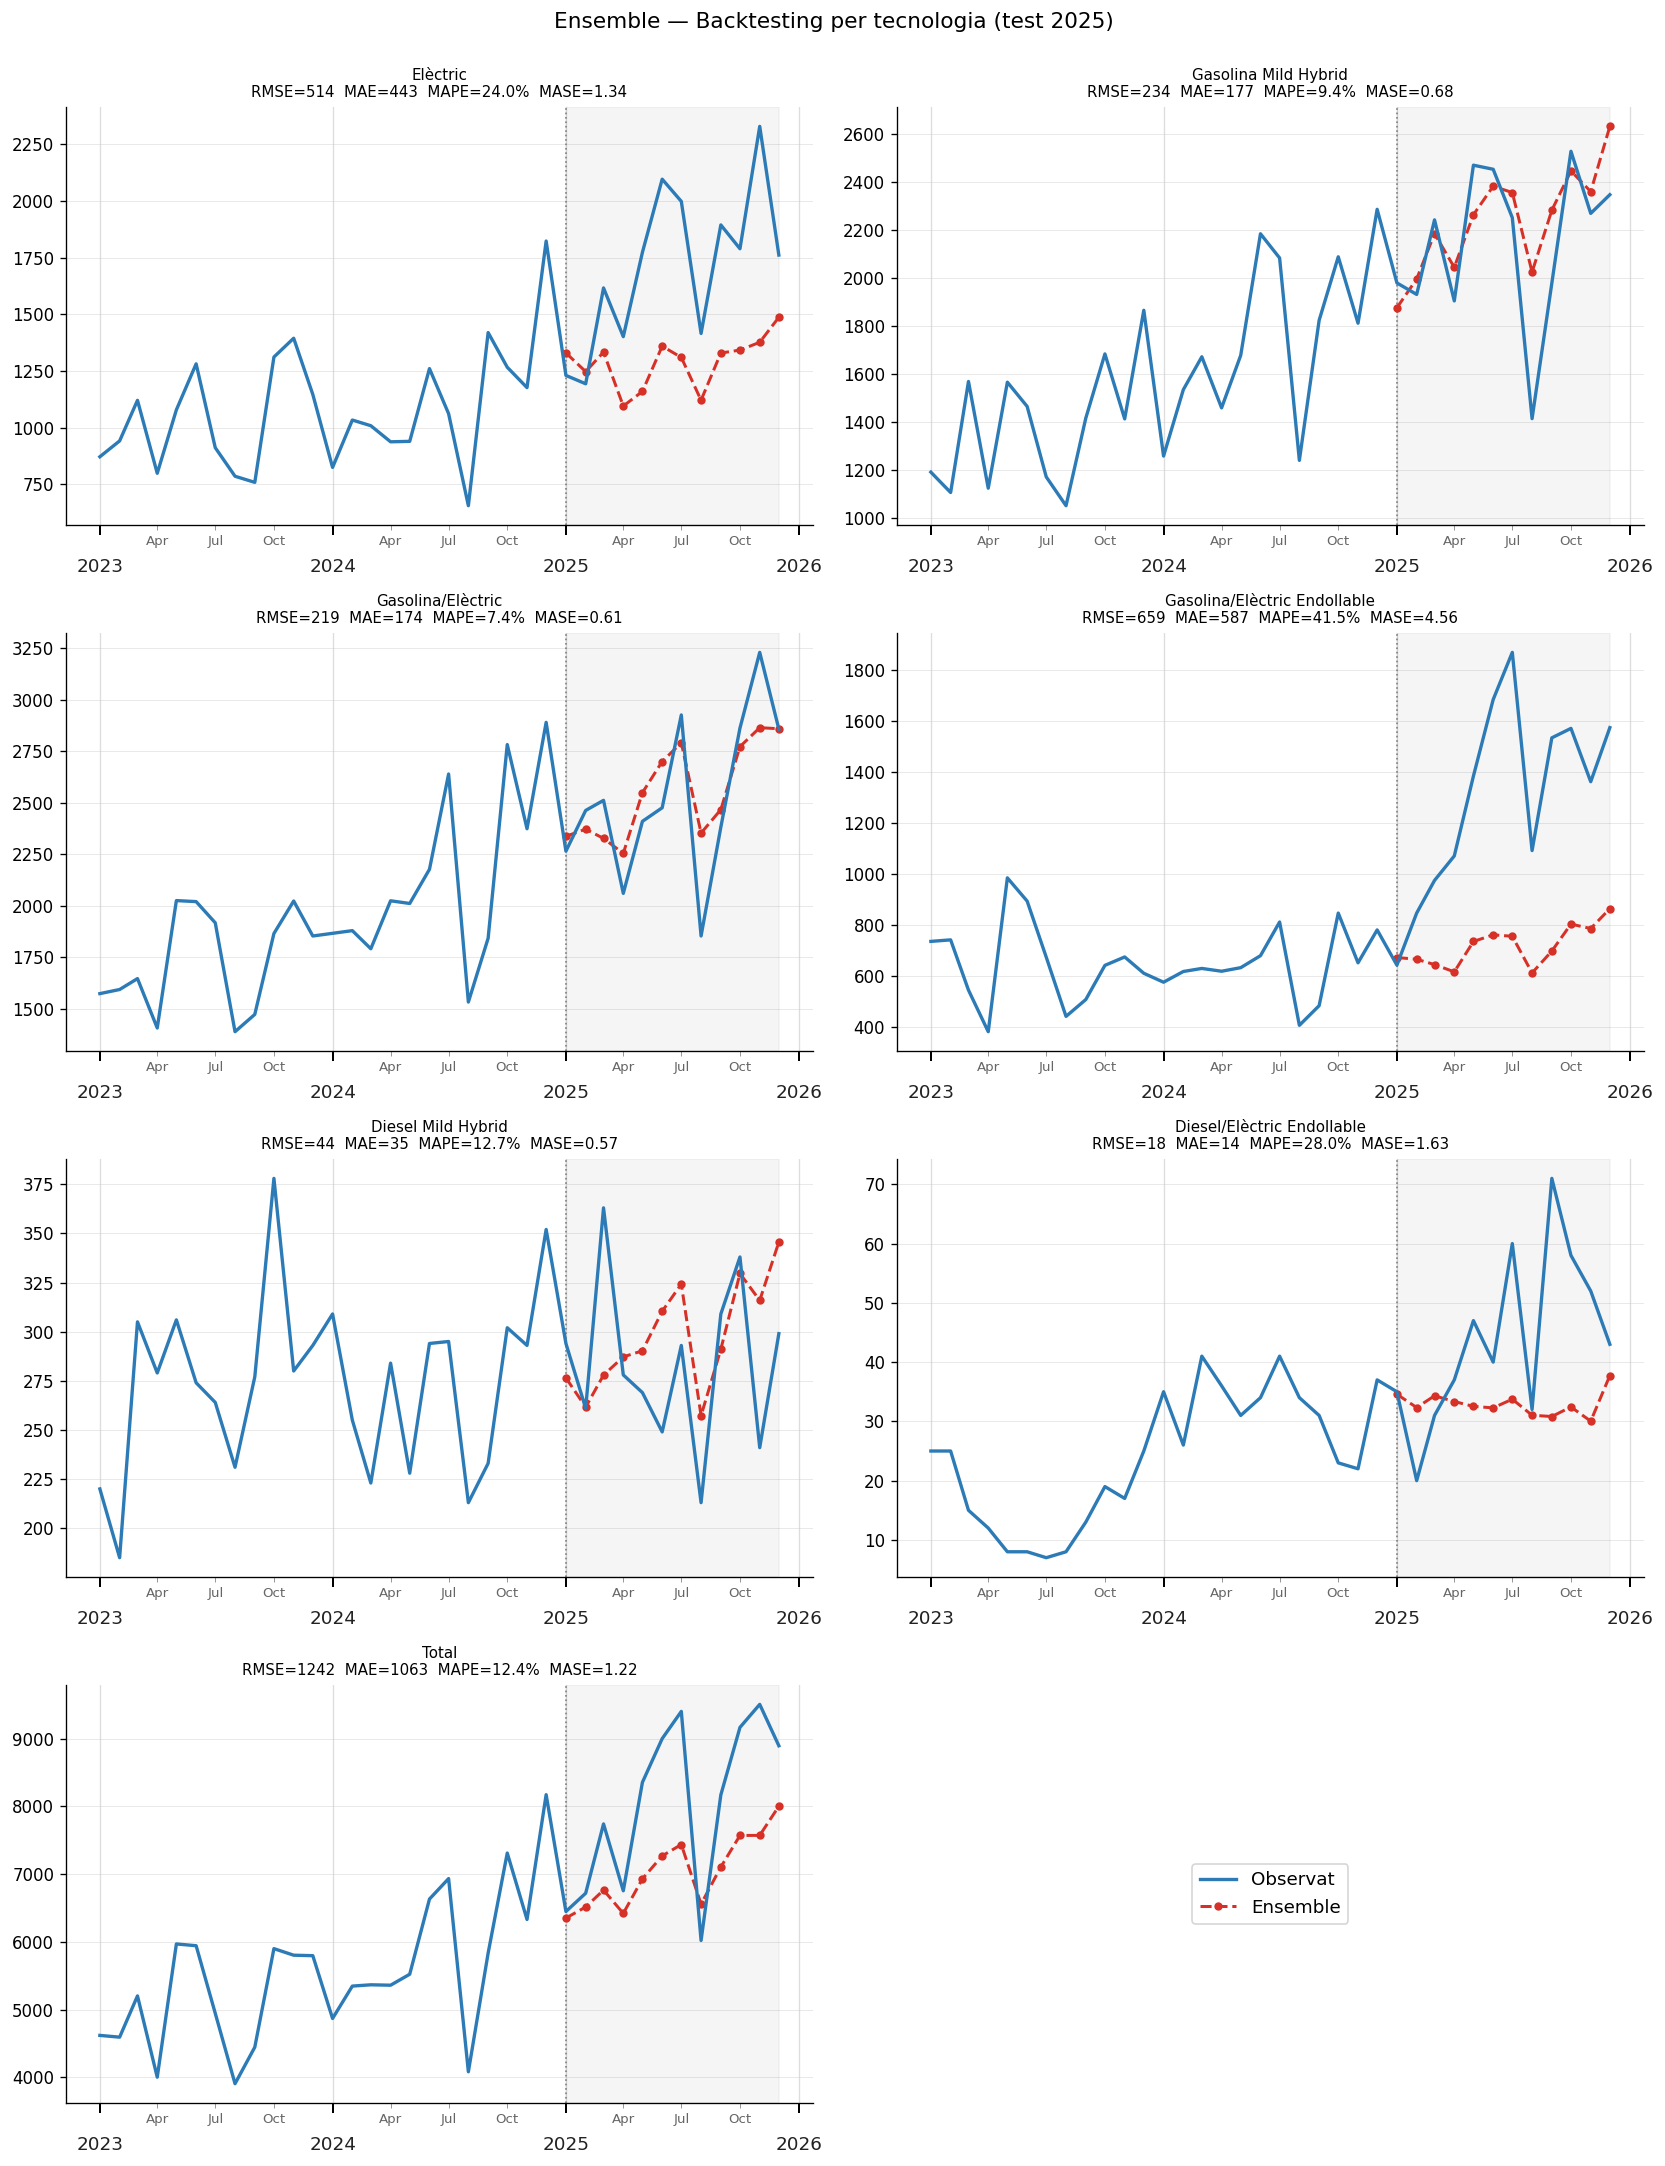

In [5]:
plot_backtest_per_tech(
    pivot_train, pivot_test, df_forecasts_ens, df_metrics_ens,
    tecnologies=TECNOLOGIES, model_name='Ensemble',
    save_path=FIGURES_DIR / 'fig_ensemble_backtest_per_tech.png',
    color_pred='#d73027',
)
plt.show()

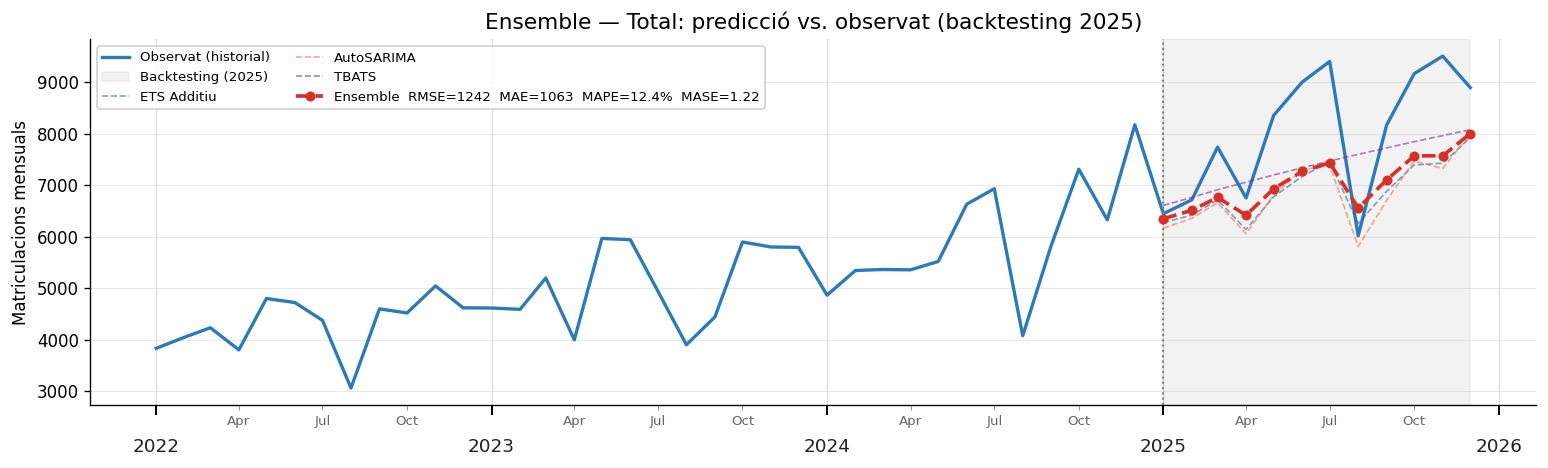

In [6]:
tech = 'Total'
sub  = df_forecasts_ens[df_forecasts_ens['Tecnologia'] == tech].sort_values('date')

fig, ax = plt.subplots(figsize=(13, 4))
y_train_plot   = pivot_train[tech].iloc[-36:]
y_test_plot    = pivot_test[tech]
observed_dates = list(y_train_plot.index) + list(y_test_plot.index)
observed_vals  = list(y_train_plot.values) + list(y_test_plot.values)
ax.plot(observed_dates, observed_vals, color='#2c7bb6', lw=2, label='Observat (historial)')
ax.axvspan(pivot_test.index[0], pivot_test.index[-1], alpha=0.10, color='gray', label='Backtesting (2025)')
ax.axvline(pivot_test.index[0], color='gray', ls=':', lw=1.2)

# Components individuals (traç fi) + Ensemble (traç gruixut)
for fc_df, model_name, color, lw, alpha in [
    (fc_ets, 'ETS Additiu',  '#2166ac', 1.0, 0.6),
    (fc_sar, 'AutoSARIMA',   '#f46d43', 1.0, 0.6),
    (fc_tbt, 'TBATS',        '#7b2d8b', 1.0, 0.6),
]:
    s = fc_df[fc_df['Tecnologia'] == tech].sort_values('date')
    ax.plot(s['date'], s['predicted'], color=color, lw=lw, ls='--', alpha=alpha, label=model_name)

m_total = df_metrics_ens[df_metrics_ens['Tecnologia'] == tech].iloc[0]
label = (f'Ensemble  RMSE={m_total["RMSE"]:.0f}  MAE={m_total["MAE"]:.0f}  '
         f'MAPE={m_total["MAPE"]:.1f}%  MASE={m_total["MASE"]:.2f}')
ax.plot(sub['date'], sub['predicted'], color='#d73027', lw=2.2, ls='--', marker='o', ms=5, label=label)

ax.set_title(f'Ensemble — {tech}: predicció vs. observat (backtesting 2025)', fontsize=13)
ax.set_ylabel('Matriculacions mensuals')
ax.legend(fontsize=8, framealpha=0.9, ncol=2)
format_ts_ax(ax)
plt.tight_layout()
plt.savefig(FIGURES_DIR / 'fig_22_ensemble_total.png', bbox_inches='tight')
plt.show()

### 1.4 Walk-forward validation (rolling-origin)

Per a l'Ensemble, el WFV no requereix cap nou entrenament: simplement combinem les prediccions WFV dels tres components (ja calculades i guardades) amb la mateixa lògica de mitjana aritmètica. Per a cada combinació (Tecnologia, fold, horitzó h), la predicció de l'Ensemble és la mitjana de les prediccions ETS Additiu, AutoSARIMA i TBATS al mateix fold i horitzó. Les mètriques per fold es computen sobre les 12 prediccions del horitzó complet.

In [7]:
# Carregar WFV forecasts dels 3 components
wfv_baseline = pd.read_csv(RESULTS_DIR / 'baseline_wfv_forecasts.csv', parse_dates=['fold_start', 'date'])
wfv_sarima   = pd.read_csv(RESULTS_DIR / 'sarima_wfv_forecasts.csv',   parse_dates=['fold_start', 'date'])
wfv_tbats_f  = pd.read_csv(RESULTS_DIR / 'tbats_wfv_forecasts.csv',    parse_dates=['fold_start', 'date'])

wfv_ets = wfv_baseline[wfv_baseline['Model'] == 'ETS_Additiu'].copy()
wfv_sar = wfv_sarima[wfv_sarima['Model'] == 'AutoSARIMA'].copy()
wfv_tbt = wfv_tbats_f[wfv_tbats_f['Model'] == 'TBATS'].copy()

key_wfv = ['Tecnologia', 'fold_start', 'h', 'date']
ens_wfv_fc = (wfv_ets[key_wfv + ['predicted', 'actual']]
              .merge(wfv_sar[key_wfv + ['predicted']].rename(columns={'predicted': 'pred_sar'}), on=key_wfv)
              .merge(wfv_tbt[key_wfv + ['predicted']].rename(columns={'predicted': 'pred_tbt'}), on=key_wfv))
ens_wfv_fc['predicted'] = (ens_wfv_fc['predicted'] + ens_wfv_fc['pred_sar'] + ens_wfv_fc['pred_tbt']) / 3
ens_wfv_fc = ens_wfv_fc[key_wfv + ['predicted', 'actual']].copy()
ens_wfv_fc['Model'] = 'Ensemble'

print(f'WFV Ensemble: {len(ens_wfv_fc)} registres '
      f'({ens_wfv_fc["fold_start"].nunique()} folds × {H} horitzons × {len(TECNOLOGIES)} tecns)')

WFV Ensemble: 1092 registres (13 folds × 12 horitzons × 7 tecns)


In [8]:
# Mètriques per fold (necessitem y_train de cada fold per calcular MASE)
wfv_metric_rows = []
for (tech, fold_start), group in ens_wfv_fc.groupby(['Tecnologia', 'fold_start']):
    g = group.sort_values('h')
    y_true = g['actual'].values
    y_pred = g['predicted'].values
    fold_pos = pivot_full.index.get_loc(fold_start)
    y_train  = pivot_full[tech].iloc[:fold_pos].dropna().values
    m = compute_metrics(y_true, y_pred, y_train)
    m.update({'fold_start': fold_start, 'n_train': fold_pos, 'Tecnologia': tech, 'Model': 'Ensemble'})
    wfv_metric_rows.append(m)

df_wfv_metrics_ens  = pd.DataFrame(wfv_metric_rows)
df_wfv_forecasts_ens = ens_wfv_fc.copy()

wfv_agg_ens = (df_wfv_metrics_ens.dropna(subset=['MASE'])
               .groupby('Tecnologia')[['RMSE','MAE','MAPE','MASE']]
               .mean().round(2).reset_index())

print('Mitjana WFV Ensemble per tecnologia:')
display(wfv_agg_ens.set_index('Tecnologia'))
global_mase = df_wfv_metrics_ens.dropna(subset=['MASE'])['MASE'].mean()
print(f'\nMASE global WFV (91 folds): {global_mase:.3f}')

Mitjana WFV Ensemble per tecnologia:


,RMSE,MAE,MAPE,MASE
Tecnologia,,,,
Diesel Mild Hybrid,49.77,40.03,16.04,0.61
Diesel/Elèctric Endollable,12.38,10.08,62.70,1.46
Elèctric,312.11,257.26,22.94,0.72
Gasolina Mild Hybrid,225.24,184.25,12.04,0.76
Gasolina/Elèctric,311.89,248.99,12.61,0.97
Gasolina/Elèctric Endollable,253.29,211.82,26.22,1.71
Total,832.06,687.00,11.58,0.80



MASE global WFV (91 folds): 1.007


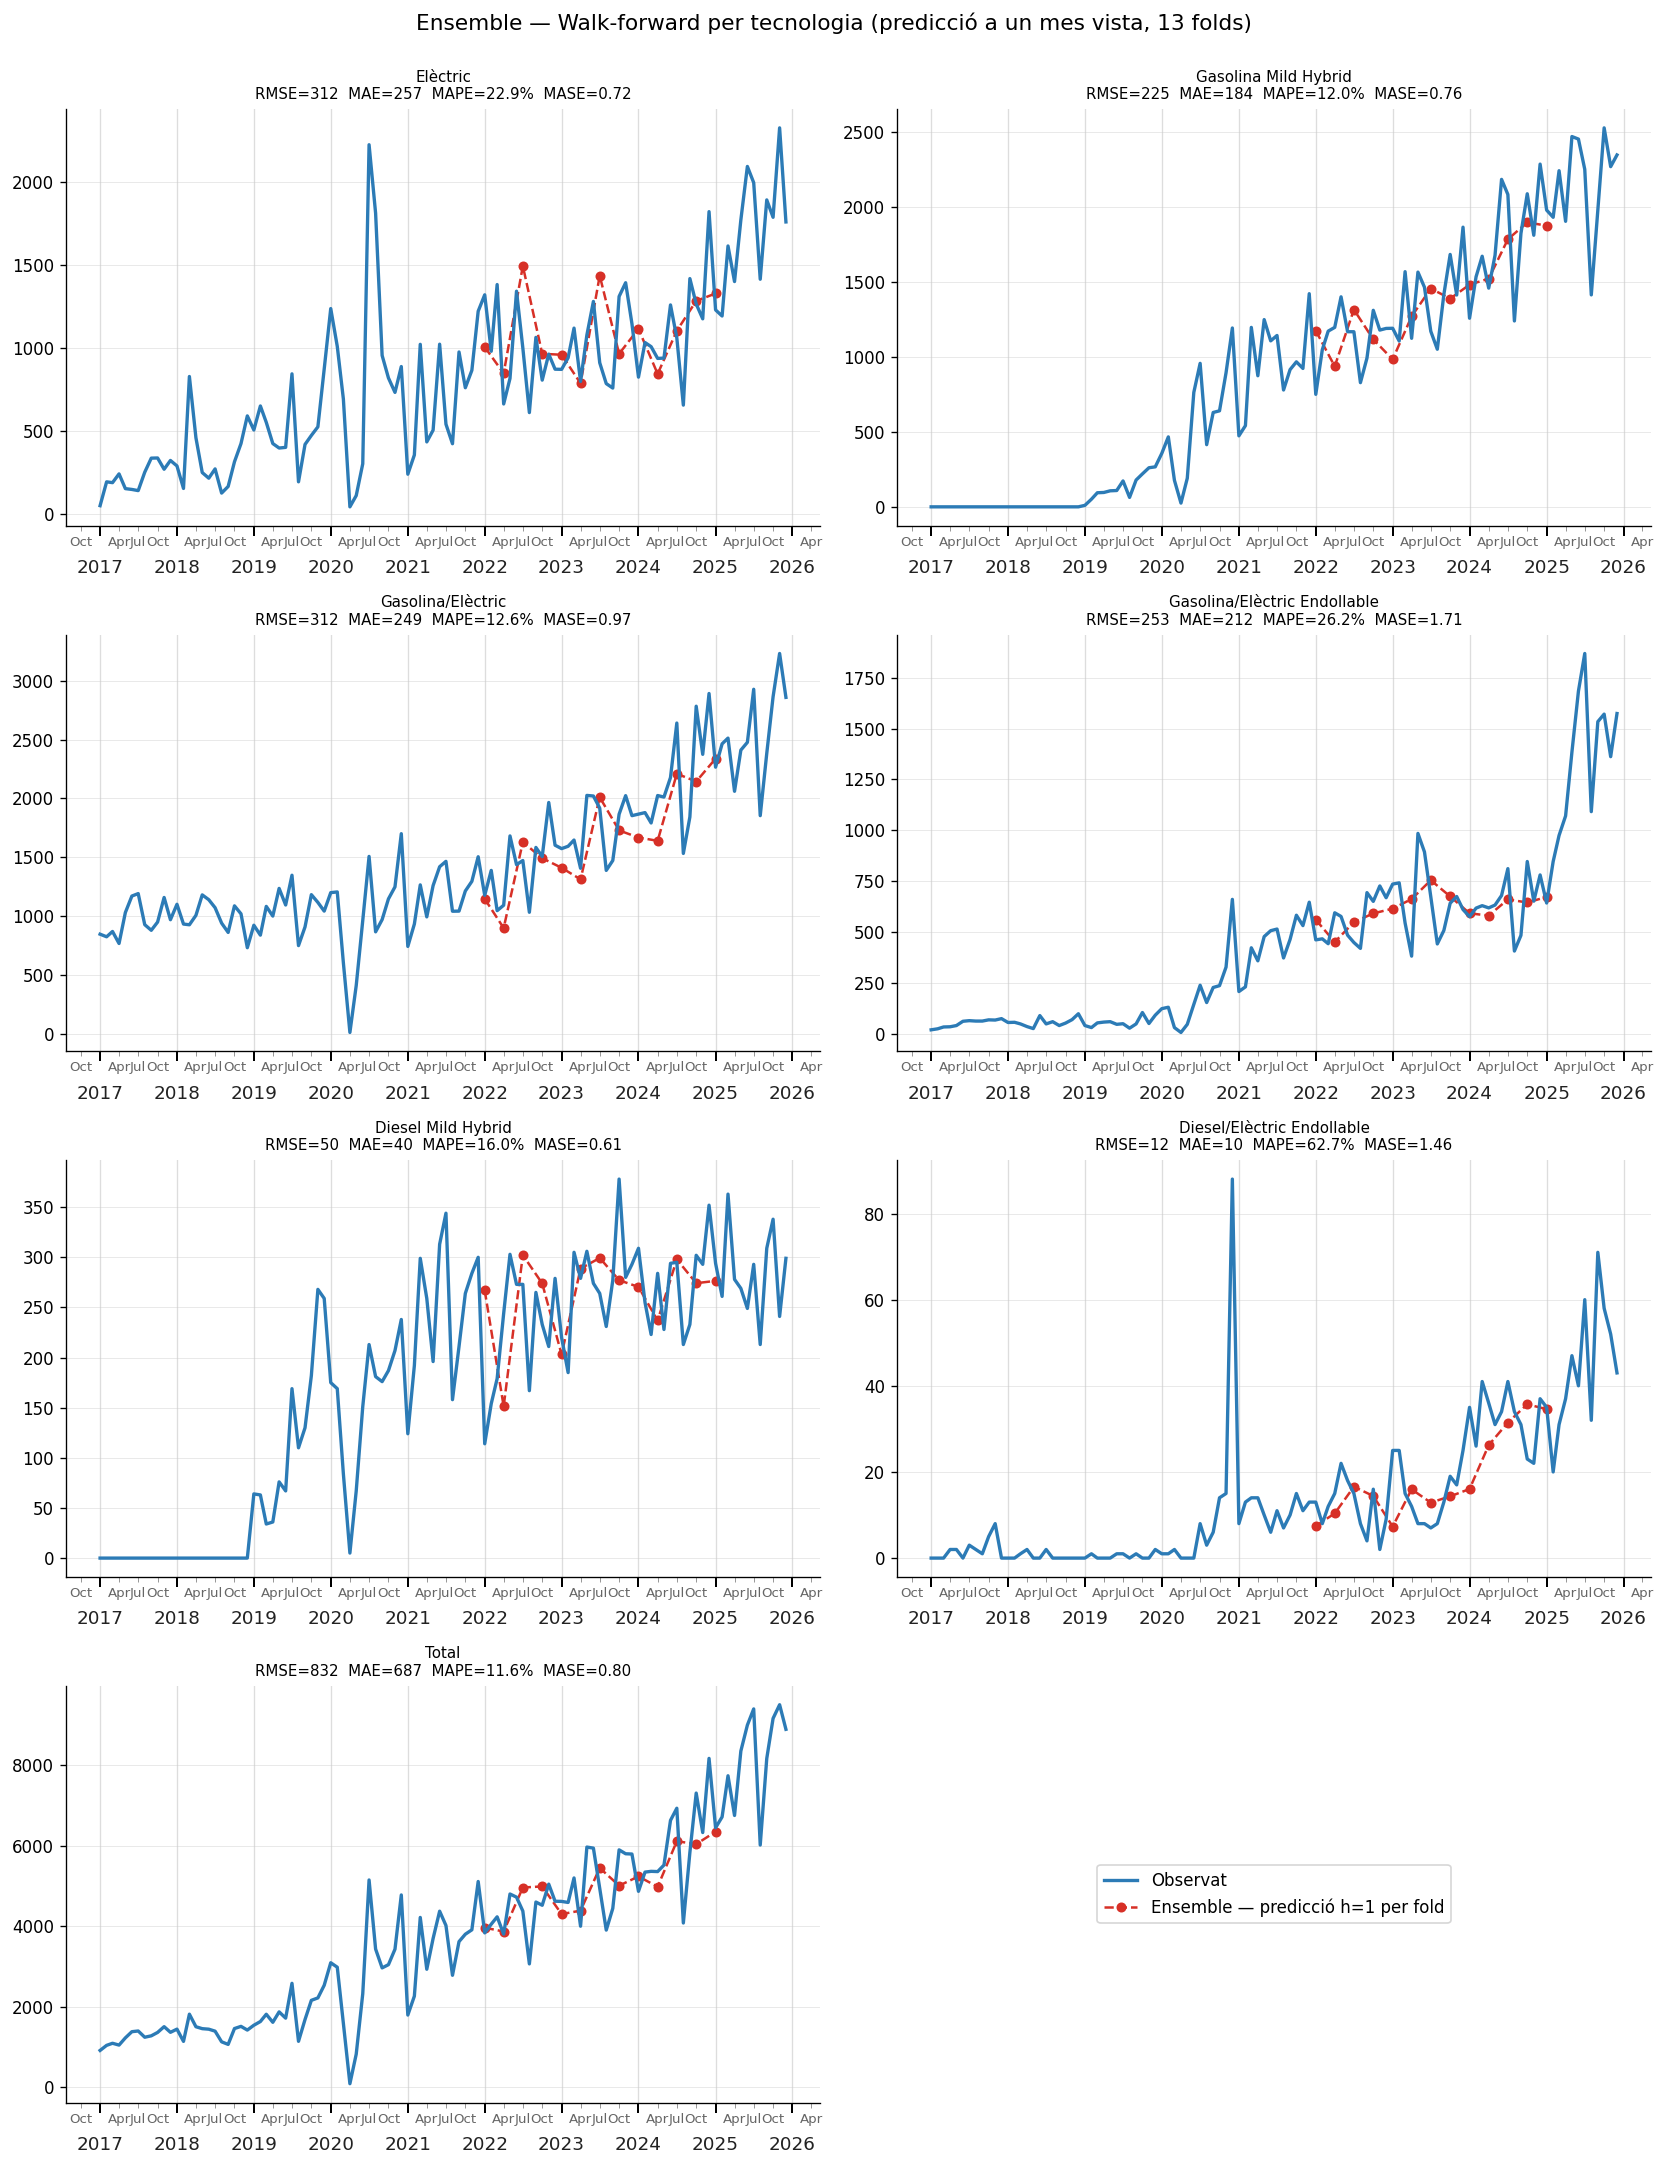

In [9]:
plot_wfv_per_tech(
    pivot_full, df_wfv_forecasts_ens, wfv_agg_ens,
    tecnologies=TECNOLOGIES, model_name='Ensemble',
    save_path=FIGURES_DIR / 'fig_23_ensemble_wfv_per_tech.png',
    color_pred='#d73027',
)
plt.show()

In [10]:
# Guardar resultats Ensemble
df_forecasts_ens.to_csv(RESULTS_DIR / 'ensemble_forecasts.csv', index=False)
df_metrics_ens.to_csv(RESULTS_DIR  / 'ensemble_metrics.csv',   index=False)
df_wfv_metrics_ens.to_csv(RESULTS_DIR  / 'ensemble_wfv_metrics.csv',   index=False)
df_wfv_forecasts_ens.to_csv(RESULTS_DIR / 'ensemble_wfv_forecasts.csv', index=False)
print('Guardats: ensemble_forecasts.csv, ensemble_metrics.csv')
print('          ensemble_wfv_metrics.csv, ensemble_wfv_forecasts.csv')

Guardats: ensemble_forecasts.csv, ensemble_metrics.csv
          ensemble_wfv_metrics.csv, ensemble_wfv_forecasts.csv


---
## Secció 2: Global LightGBM (cross-series)

### 2.1 Motivació i disseny

El LightGBM individual del benchmark obtenia un WFV MASE=1.47, clarament per sota del SeasonalNaive (1.30). El motiu és estructural: amb N≈84 mostres per sèrie i estacionalitat anual m=12, el gradient boosting no disposa de prou dades per aprendre l'estructura estacional implícitament. En canvi, els models estadístics capturen l'estacionalitat via paràmetres explícits (coeficients AR, sinus/cosinus de Fourier, suavitzat exponencial), que s'estimen amb molta eficiència amb N petit.

La solució és **compartir la força estadística entre sèries** (*cross-learning* o *global model*). En lloc d'entrenar 7 models separats (un per tecnologia), entrenem un sol model LightGBM sobre la matriu de features concatenada de les 7 sèries: 7 × 84 ≈ 588 observacions. Mantenim l'estratègia *direct multi-step*: un model per a cada horitzó h=1..12.

Per diferenciar les tecnologies, afegim una variable `tech_id` (enter 0–6) marcada com a **categòrica** a LightGBM. Això permet als arbres de decisió partir explícitament per tecnologia quan és útil (per exemple, el pic de Gasolina/Elèctric és diferent del d'Elèctric pur) i compartir representació quan l'estacionalitat és similar.

| Paràmetre | Valor | Raó |
|---|---|---|
| Arquitectura | 1 model per h (direct multi-step) | Evita propagació d'errors recursiva |
| Dades d'entrenament | 7 sèries concatenades | 7× més dades per aprendre estacionalitat |
| Diferenciació de sèrie | `tech_id` categòric (0–6) | LightGBM parteix per tech quan millora |
| Hiperparàmetres | Idèntics al LGBM individual | Comparació justa |

### 2.2 Entrenament — backtest 2025

In [11]:
# Construir la matriu global de features i els targets per horitzó
all_X_h = {h: [] for h in range(1, H + 1)}
all_y_h = {h: [] for h in range(1, H + 1)}
X_last_per_tech = {}

for i_tech, tech in enumerate(TECNOLOGIES):
    df_tech = train_set[train_set['Tecnologia'] == tech][['date', 'Matriculacions']].copy()
    df_feat = build_ml_features(df_tech)
    df_clean = df_feat.dropna(subset=FEATURE_COLS).copy()
    df_clean['tech_id'] = i_tech

    X = df_clean[FEATURE_COLS_G].values
    y = df_clean['Matriculacions'].values

    for h in range(1, H + 1):
        n_valid = len(y) - h
        if n_valid <= 0:
            continue
        all_X_h[h].append(pd.DataFrame(X[:n_valid], columns=FEATURE_COLS_G))
        all_y_h[h].append(y[h:])

    # Fila de predicció: última fila del train complet (amb tots els lags disponibles)
    X_last = df_feat[FEATURE_COLS].iloc[[-1]].copy()
    X_last['tech_id'] = i_tech
    X_last_per_tech[tech] = X_last[FEATURE_COLS_G].copy()

# Entrenar un model per horitzó
models_global = {}
for h in range(1, H + 1):
    X_h_df = pd.concat(all_X_h[h], ignore_index=True)
    y_h    = np.concatenate(all_y_h[h])
    model  = lgb.LGBMRegressor(**LGB_PARAMS)
    model.fit(X_h_df, y_h, categorical_feature=['tech_id'])
    models_global[h] = model

n_train_global = len(pd.concat(all_X_h[1], ignore_index=True))
print(f'Matriu global h=1: {n_train_global} observacions × {len(FEATURE_COLS_G)} features')
print(f'Entrenats {len(models_global)} models globals (h=1..{H})')

Matriu global h=1: 581 observacions × 19 features
Entrenats 12 models globals (h=1..12)


In [12]:
# Predicció i mètriques
forecast_records_g = []
metrics_records_g  = []

for tech in TECNOLOGIES:
    y_pred  = np.array([max(models_global[h].predict(X_last_per_tech[tech])[0], 0)
                        for h in range(1, H + 1)])
    y_test  = pivot_test[tech].values
    y_train = pivot_train[tech].dropna().values

    m = compute_metrics(y_test, y_pred, y_train)
    m.update({'Tecnologia': tech, 'Model': 'GlobalLGBM'})
    metrics_records_g.append(m)
    print(f'  {tech:35s}: RMSE={m["RMSE"]:.0f}, MAPE={m["MAPE"]:.1f}%, MASE={m["MASE"]:.2f}')

    for i, date in enumerate(pivot_test.index):
        forecast_records_g.append({'date': date, 'Tecnologia': tech, 'Model': 'GlobalLGBM',
                                   'predicted': y_pred[i], 'actual': y_test[i]})

df_metrics_g   = pd.DataFrame(metrics_records_g)
df_forecasts_g = pd.DataFrame(forecast_records_g)

avg_g = df_metrics_g[['RMSE','MAE','MAPE','MASE']].mean().round(2)
print(f'\nMitjana global → RMSE={avg_g["RMSE"]:.0f}, MAPE={avg_g["MAPE"]:.1f}%, MASE={avg_g["MASE"]:.2f}')

  Elèctric                           : RMSE=347, MAPE=15.2%, MASE=0.85
  Gasolina Mild Hybrid               : RMSE=672, MAPE=27.1%, MASE=2.07
  Gasolina/Elèctric                  : RMSE=874, MAPE=31.6%, MASE=2.67
  Gasolina/Elèctric Endollable       : RMSE=543, MAPE=36.4%, MASE=3.82
  Diesel Mild Hybrid                 : RMSE=151, MAPE=50.1%, MASE=2.18
  Diesel/Elèctric Endollable         : RMSE=137, MAPE=313.2%, MASE=14.34
  Total                              : RMSE=1770, MAPE=16.9%, MASE=1.68

Mitjana global → RMSE=642, MAPE=70.1%, MASE=3.95


### 2.3 Feature Importance — h=1 (Global)

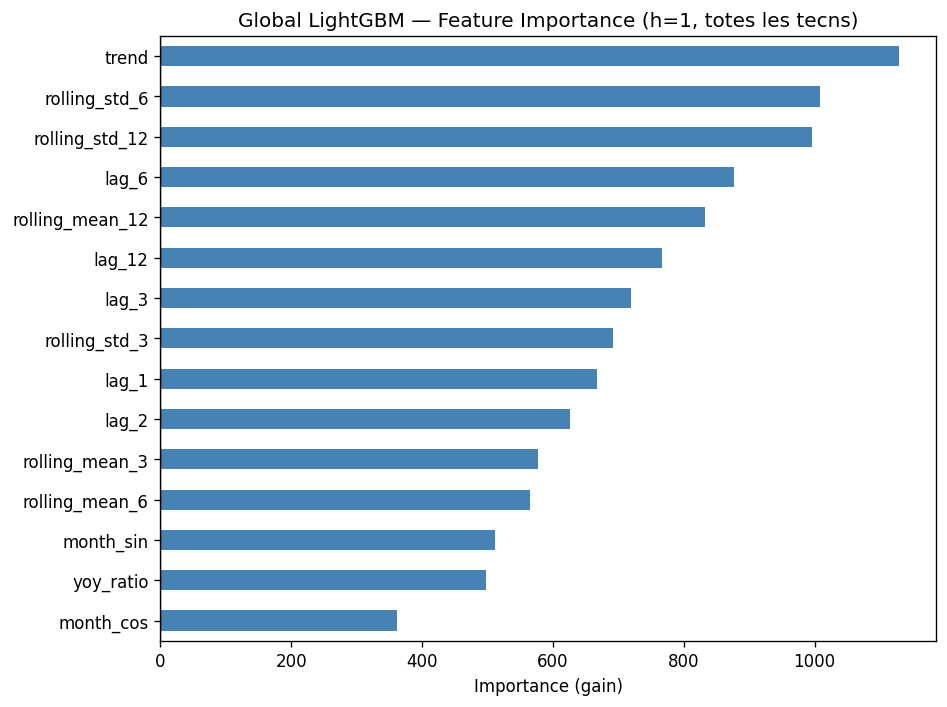


Importància de tech_id: 64 (posició 18 de 19


In [13]:
model_h1 = models_global[1]
importance = pd.Series(model_h1.feature_importances_,
                       index=FEATURE_COLS_G).sort_values(ascending=True)

fig, ax = plt.subplots(figsize=(8, 6))
colors_imp = ['#d73027' if f == 'tech_id' else 'steelblue' for f in importance.tail(15).index]
importance.tail(15).plot.barh(ax=ax, color=colors_imp)
ax.set_title('Global LightGBM — Feature Importance (h=1, totes les tecns)', fontsize=12)
ax.set_xlabel('Importance (gain)')
ax.axvline(0, color='black', lw=0.8)
# Anotació tech_id
if 'tech_id' in importance.tail(15).index:
    rank = list(importance.tail(15).index).index('tech_id')
    ax.text(importance['tech_id'] * 1.02, rank, 'tech_id (nou)', va='center', fontsize=8, color='#d73027')
plt.tight_layout()
plt.savefig(FIGURES_DIR / 'fig_global_lgbm_importance.png', bbox_inches='tight')
plt.show()

print(f"\nImportància de tech_id: {importance['tech_id']:.0f} "
      f"(posició {len(importance) - importance.rank().astype(int)['tech_id'] + 1} de {len(importance)}")

### 2.4 Visualització — backtesting per tecnologia

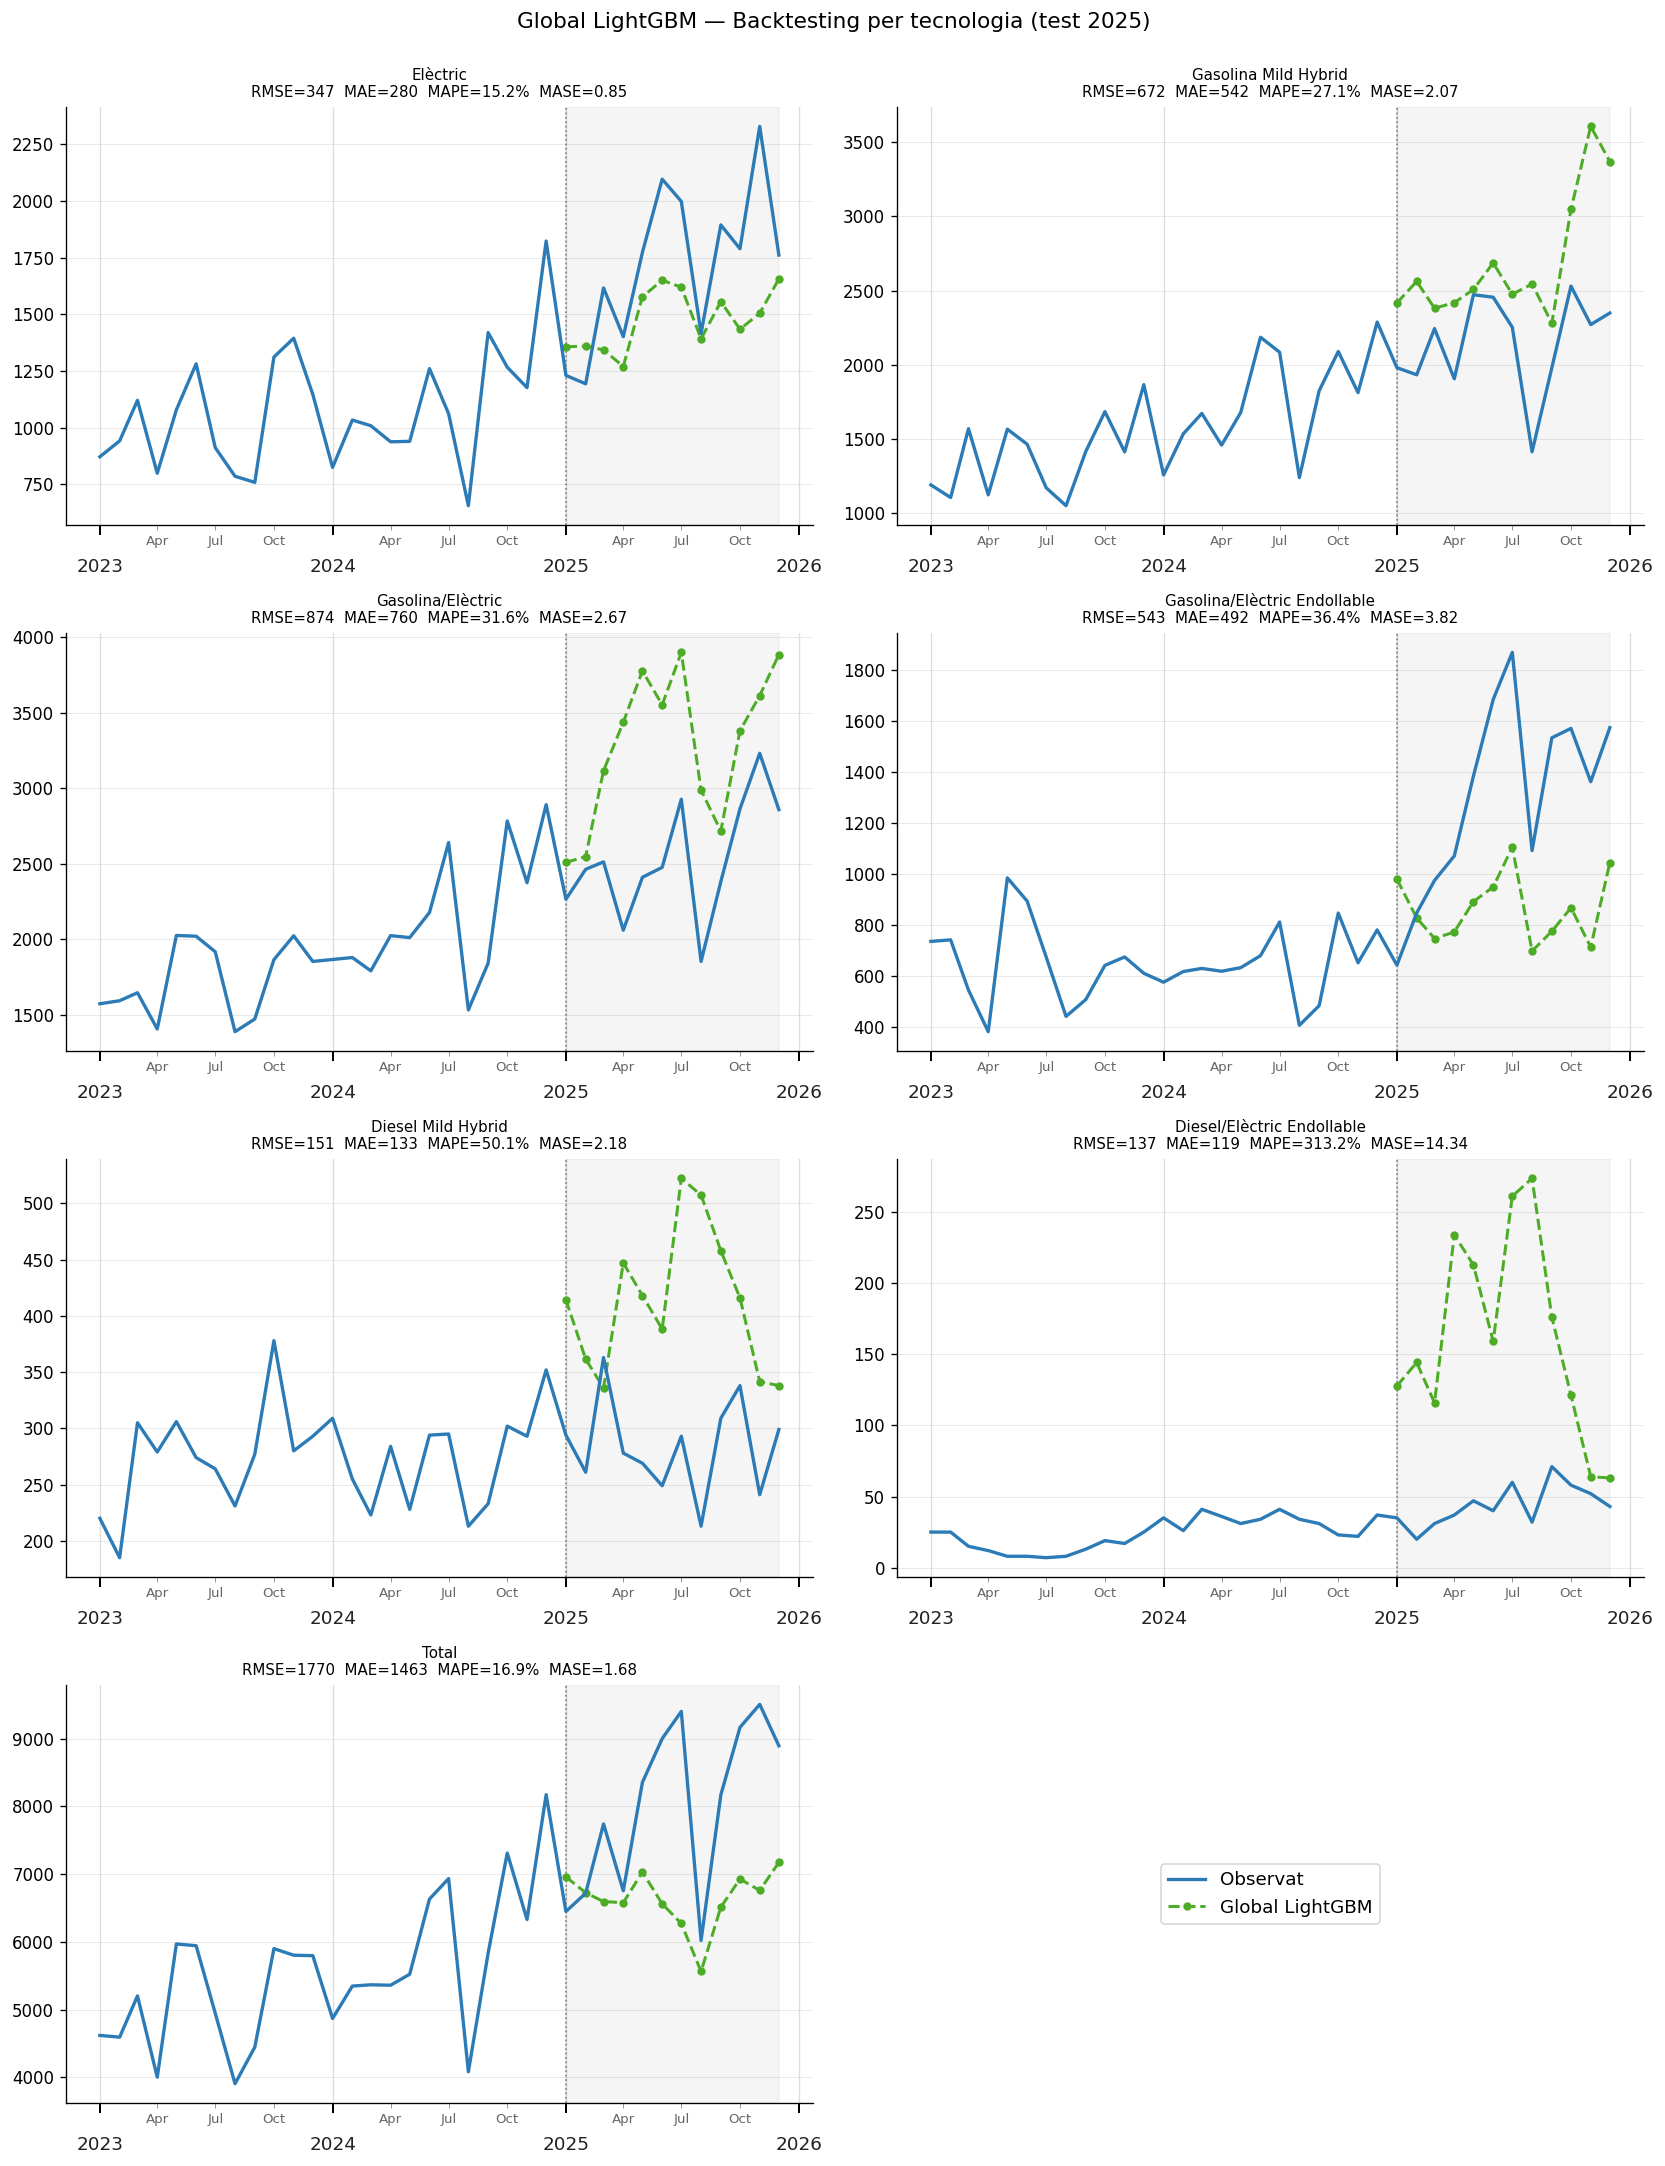

In [14]:
plot_backtest_per_tech(
    pivot_train, pivot_test, df_forecasts_g, df_metrics_g,
    tecnologies=TECNOLOGIES, model_name='Global LightGBM',
    save_path=FIGURES_DIR / 'fig_global_lgbm_backtest_per_tech.png',
    color_pred='#4dac26',
)
plt.show()

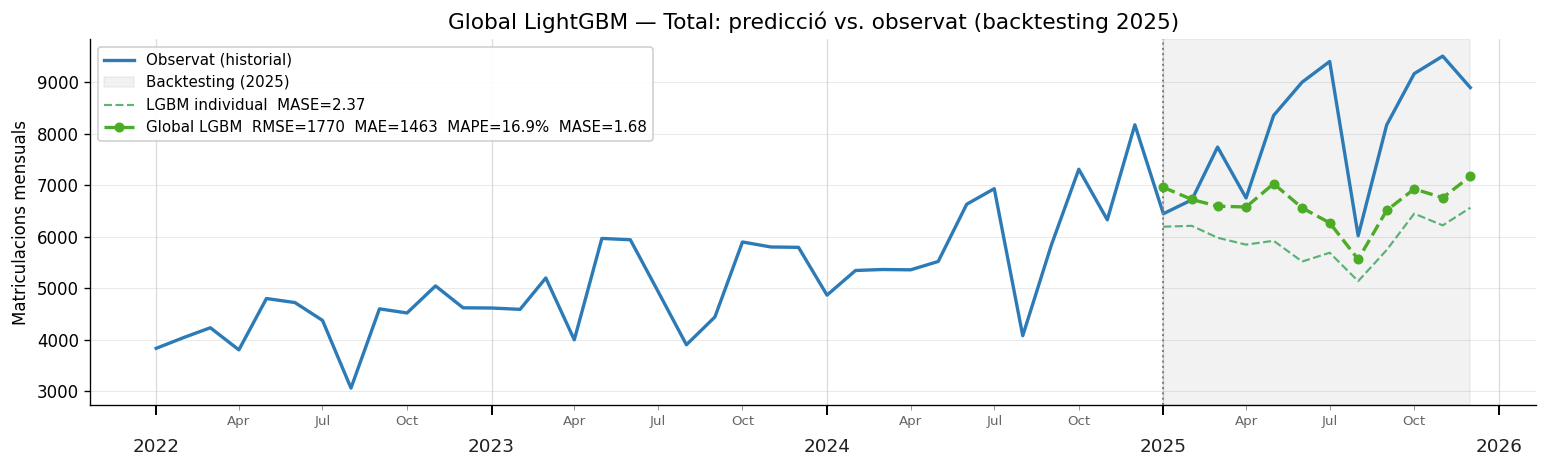

In [15]:
tech = 'Total'
# Comparació directa: LGBM individual vs Global LGBM
lgbm_ind = pd.read_csv(RESULTS_DIR / 'lgbm_forecasts.csv', parse_dates=['date'])
lgbm_ind = lgbm_ind[lgbm_ind['Tecnologia'] == tech].sort_values('date')

fig, ax = plt.subplots(figsize=(13, 4))
y_train_plot   = pivot_train[tech].iloc[-36:]
y_test_plot    = pivot_test[tech]
observed_dates = list(y_train_plot.index) + list(y_test_plot.index)
observed_vals  = list(y_train_plot.values) + list(y_test_plot.values)
ax.plot(observed_dates, observed_vals, color='#2c7bb6', lw=2, label='Observat (historial)')
ax.axvspan(pivot_test.index[0], pivot_test.index[-1], alpha=0.10, color='gray', label='Backtesting (2025)')
ax.axvline(pivot_test.index[0], color='gray', ls=':', lw=1.2)

lgbm_m = pd.read_csv(RESULTS_DIR / 'lgbm_metrics.csv')
lgbm_m_tot = lgbm_m[lgbm_m['Tecnologia'] == tech].iloc[0]
ax.plot(lgbm_ind['date'], lgbm_ind['predicted'], color='#1a9641', lw=1.3, ls='--',
        label=f'LGBM individual  MASE={lgbm_m_tot["MASE"]:.2f}', alpha=0.7)

sub_g = df_forecasts_g[df_forecasts_g['Tecnologia'] == tech].sort_values('date')
m_g   = df_metrics_g[df_metrics_g['Tecnologia'] == tech].iloc[0]
label = (f'Global LGBM  RMSE={m_g["RMSE"]:.0f}  MAE={m_g["MAE"]:.0f}  '
         f'MAPE={m_g["MAPE"]:.1f}%  MASE={m_g["MASE"]:.2f}')
ax.plot(sub_g['date'], sub_g['predicted'], color='#4dac26', lw=2, ls='--',
        marker='o', ms=5, label=label)

ax.set_title(f'Global LightGBM — {tech}: predicció vs. observat (backtesting 2025)', fontsize=13)
ax.set_ylabel('Matriculacions mensuals')
ax.legend(fontsize=9, framealpha=0.9)
format_ts_ax(ax)
plt.tight_layout()
plt.savefig(FIGURES_DIR / 'fig_24_global_lgbm_total.png', bbox_inches='tight')
plt.show()

### 2.5 Walk-forward validation (rolling-origin)

El WFV del Global LightGBM requereix un bucle personalitzat: a cada fold s'ha de reconstruir la matriu global de features (les 7 sèries concatenades fins al punt d'origin) i reentrenar els 12 models. El cost aproximat és proporcional al del LGBM individual però amb 7× més dades per model: **~15-25 minuts en total** (13 folds × 12 models).

Per cada fold amb origin a `start`:
1. Per a cada tecnologia, construïm features sobre `pivot_full[tech].iloc[:start]`.
2. Concatenem les 7 matrius (amb `tech_id`) per formar la matriu global.
3. Entrenem 12 models (`h=1..12`) sobre la matriu global.
4. Predim els 12 mesos de test (`pivot_full[tech].iloc[start:start+12]`) per a cada tecnologia.

In [16]:
INITIAL, STEP = 60, 3
n_full = len(pivot_full)
fold_starts = list(range(INITIAL, n_full - H + 1, STEP))
print(f'Folds: {len(fold_starts)} (origins: {pivot_full.index[INITIAL].date()} → {pivot_full.index[fold_starts[-1]].date()})')

wfv_metric_rows_g   = []
wfv_forecast_rows_g = []

t0 = time.time()
for fi, start in enumerate(fold_starts):
    # --- Construir matriu global per a aquest fold ---
    all_X_h_fold = {h: [] for h in range(1, H + 1)}
    all_y_h_fold = {h: [] for h in range(1, H + 1)}
    X_last_fold  = {}

    for i_tech, tech in enumerate(TECNOLOGIES):
        train_s = pivot_full[tech].iloc[:start].dropna()
        df_tech = pd.DataFrame({'date': train_s.index, 'Matriculacions': train_s.values})
        df_feat = build_ml_features(df_tech)
        df_clean = df_feat.dropna(subset=FEATURE_COLS).copy()
        df_clean['tech_id'] = i_tech

        if len(df_clean) < H:
            continue

        X = df_clean[FEATURE_COLS_G].values
        y = df_clean['Matriculacions'].values

        for h in range(1, H + 1):
            n_valid = len(y) - h
            if n_valid <= 0:
                continue
            all_X_h_fold[h].append(pd.DataFrame(X[:n_valid], columns=FEATURE_COLS_G))
            all_y_h_fold[h].append(y[h:])

        # X_last per a la predicció
        X_last_row = df_feat[FEATURE_COLS].iloc[[-1]].copy()
        X_last_row['tech_id'] = i_tech
        X_last_fold[tech] = X_last_row[FEATURE_COLS_G].copy()

    # --- Entrenar models globals per a aquest fold ---
    models_fold = {}
    for h in range(1, H + 1):
        if not all_X_h_fold[h]:
            continue
        X_h_df = pd.concat(all_X_h_fold[h], ignore_index=True)
        y_h    = np.concatenate(all_y_h_fold[h])
        model  = lgb.LGBMRegressor(**LGB_PARAMS)
        model.fit(X_h_df, y_h, categorical_feature=['tech_id'])
        models_fold[h] = model

    # --- Predicció per a cada tecnologia ---
    for tech in TECNOLOGIES:
        if tech not in X_last_fold:
            continue
        test_window = pivot_full[tech].iloc[start:start + H]
        if len(test_window) < H:
            continue

        y_pred = np.array([max(models_fold[h].predict(X_last_fold[tech])[0], 0)
                           for h in range(1, H + 1) if h in models_fold])
        y_true = test_window.values
        y_tr   = pivot_full[tech].iloc[:start].dropna().values

        m = compute_metrics(y_true, y_pred, y_tr)
        m.update({'fold_start': pivot_full.index[start], 'n_train': start,
                  'Tecnologia': tech, 'Model': 'GlobalLGBM'})
        wfv_metric_rows_g.append(m)

        for h_idx in range(H):
            wfv_forecast_rows_g.append({
                'fold_start': pivot_full.index[start],
                'h':          h_idx + 1,
                'date':       test_window.index[h_idx],
                'predicted':  float(y_pred[h_idx]),
                'actual':     float(y_true[h_idx]),
                'Tecnologia': tech,
                'Model':      'GlobalLGBM',
            })

    if fi % 4 == 0 or fi == len(fold_starts) - 1:
        print(f'  Fold {fi+1:2d}/{len(fold_starts)}: origin {pivot_full.index[start].strftime("%Y-%m")} '
              f'— {(time.time()-t0)/60:.1f} min')

df_wfv_metrics_g   = pd.DataFrame(wfv_metric_rows_g)
df_wfv_forecasts_g = pd.DataFrame(wfv_forecast_rows_g)
print(f'\nTotal WFV: {(time.time()-t0)/60:.1f} min')

Folds: 13 (origins: 2022-01-01 → 2025-01-01)
  Fold  1/13: origin 2022-01 — 0.1 min
  Fold  5/13: origin 2023-01 — 0.4 min
  Fold  9/13: origin 2024-01 — 0.8 min
  Fold 13/13: origin 2025-01 — 1.2 min

Total WFV: 1.2 min


In [17]:
wfv_agg_g = (df_wfv_metrics_g.dropna(subset=['MASE'])
             .groupby('Tecnologia')[['RMSE','MAE','MAPE','MASE']]
             .mean().round(2).reset_index())

print('Mitjana WFV Global LightGBM per tecnologia:')
display(wfv_agg_g.set_index('Tecnologia'))

global_mase_g = df_wfv_metrics_g.dropna(subset=['MASE'])['MASE'].mean()
print(f'\nMASE global WFV (91 folds): {global_mase_g:.3f}')

# Comparació ràpida amb LGBM individual
lgbm_wfv_m = pd.read_csv(RESULTS_DIR / 'lgbm_wfv_metrics.csv', parse_dates=['fold_start'])
lgbm_global_mase = lgbm_wfv_m.dropna(subset=['MASE'])['MASE'].mean()
print(f'MASE global WFV LGBM individual (referència): {lgbm_global_mase:.3f}')
print(f'Millora Global vs Individual: {(lgbm_global_mase - global_mase_g)/lgbm_global_mase*100:.1f}%')

Mitjana WFV Global LightGBM per tecnologia:


,RMSE,MAE,MAPE,MASE
Tecnologia,,,,
Diesel Mild Hybrid,99.40,83.05,33.34,1.27
Diesel/Elèctric Endollable,53.77,41.46,274.08,5.89
Elèctric,327.95,264.74,23.43,0.74
Gasolina Mild Hybrid,348.74,286.92,18.29,1.17
Gasolina/Elèctric,623.72,503.94,26.09,1.94
Gasolina/Elèctric Endollable,327.38,270.66,38.42,2.21
Total,1287.75,1096.11,18.03,1.28



MASE global WFV (91 folds): 2.072
MASE global WFV LGBM individual (referència): 1.471
Millora Global vs Individual: -40.8%


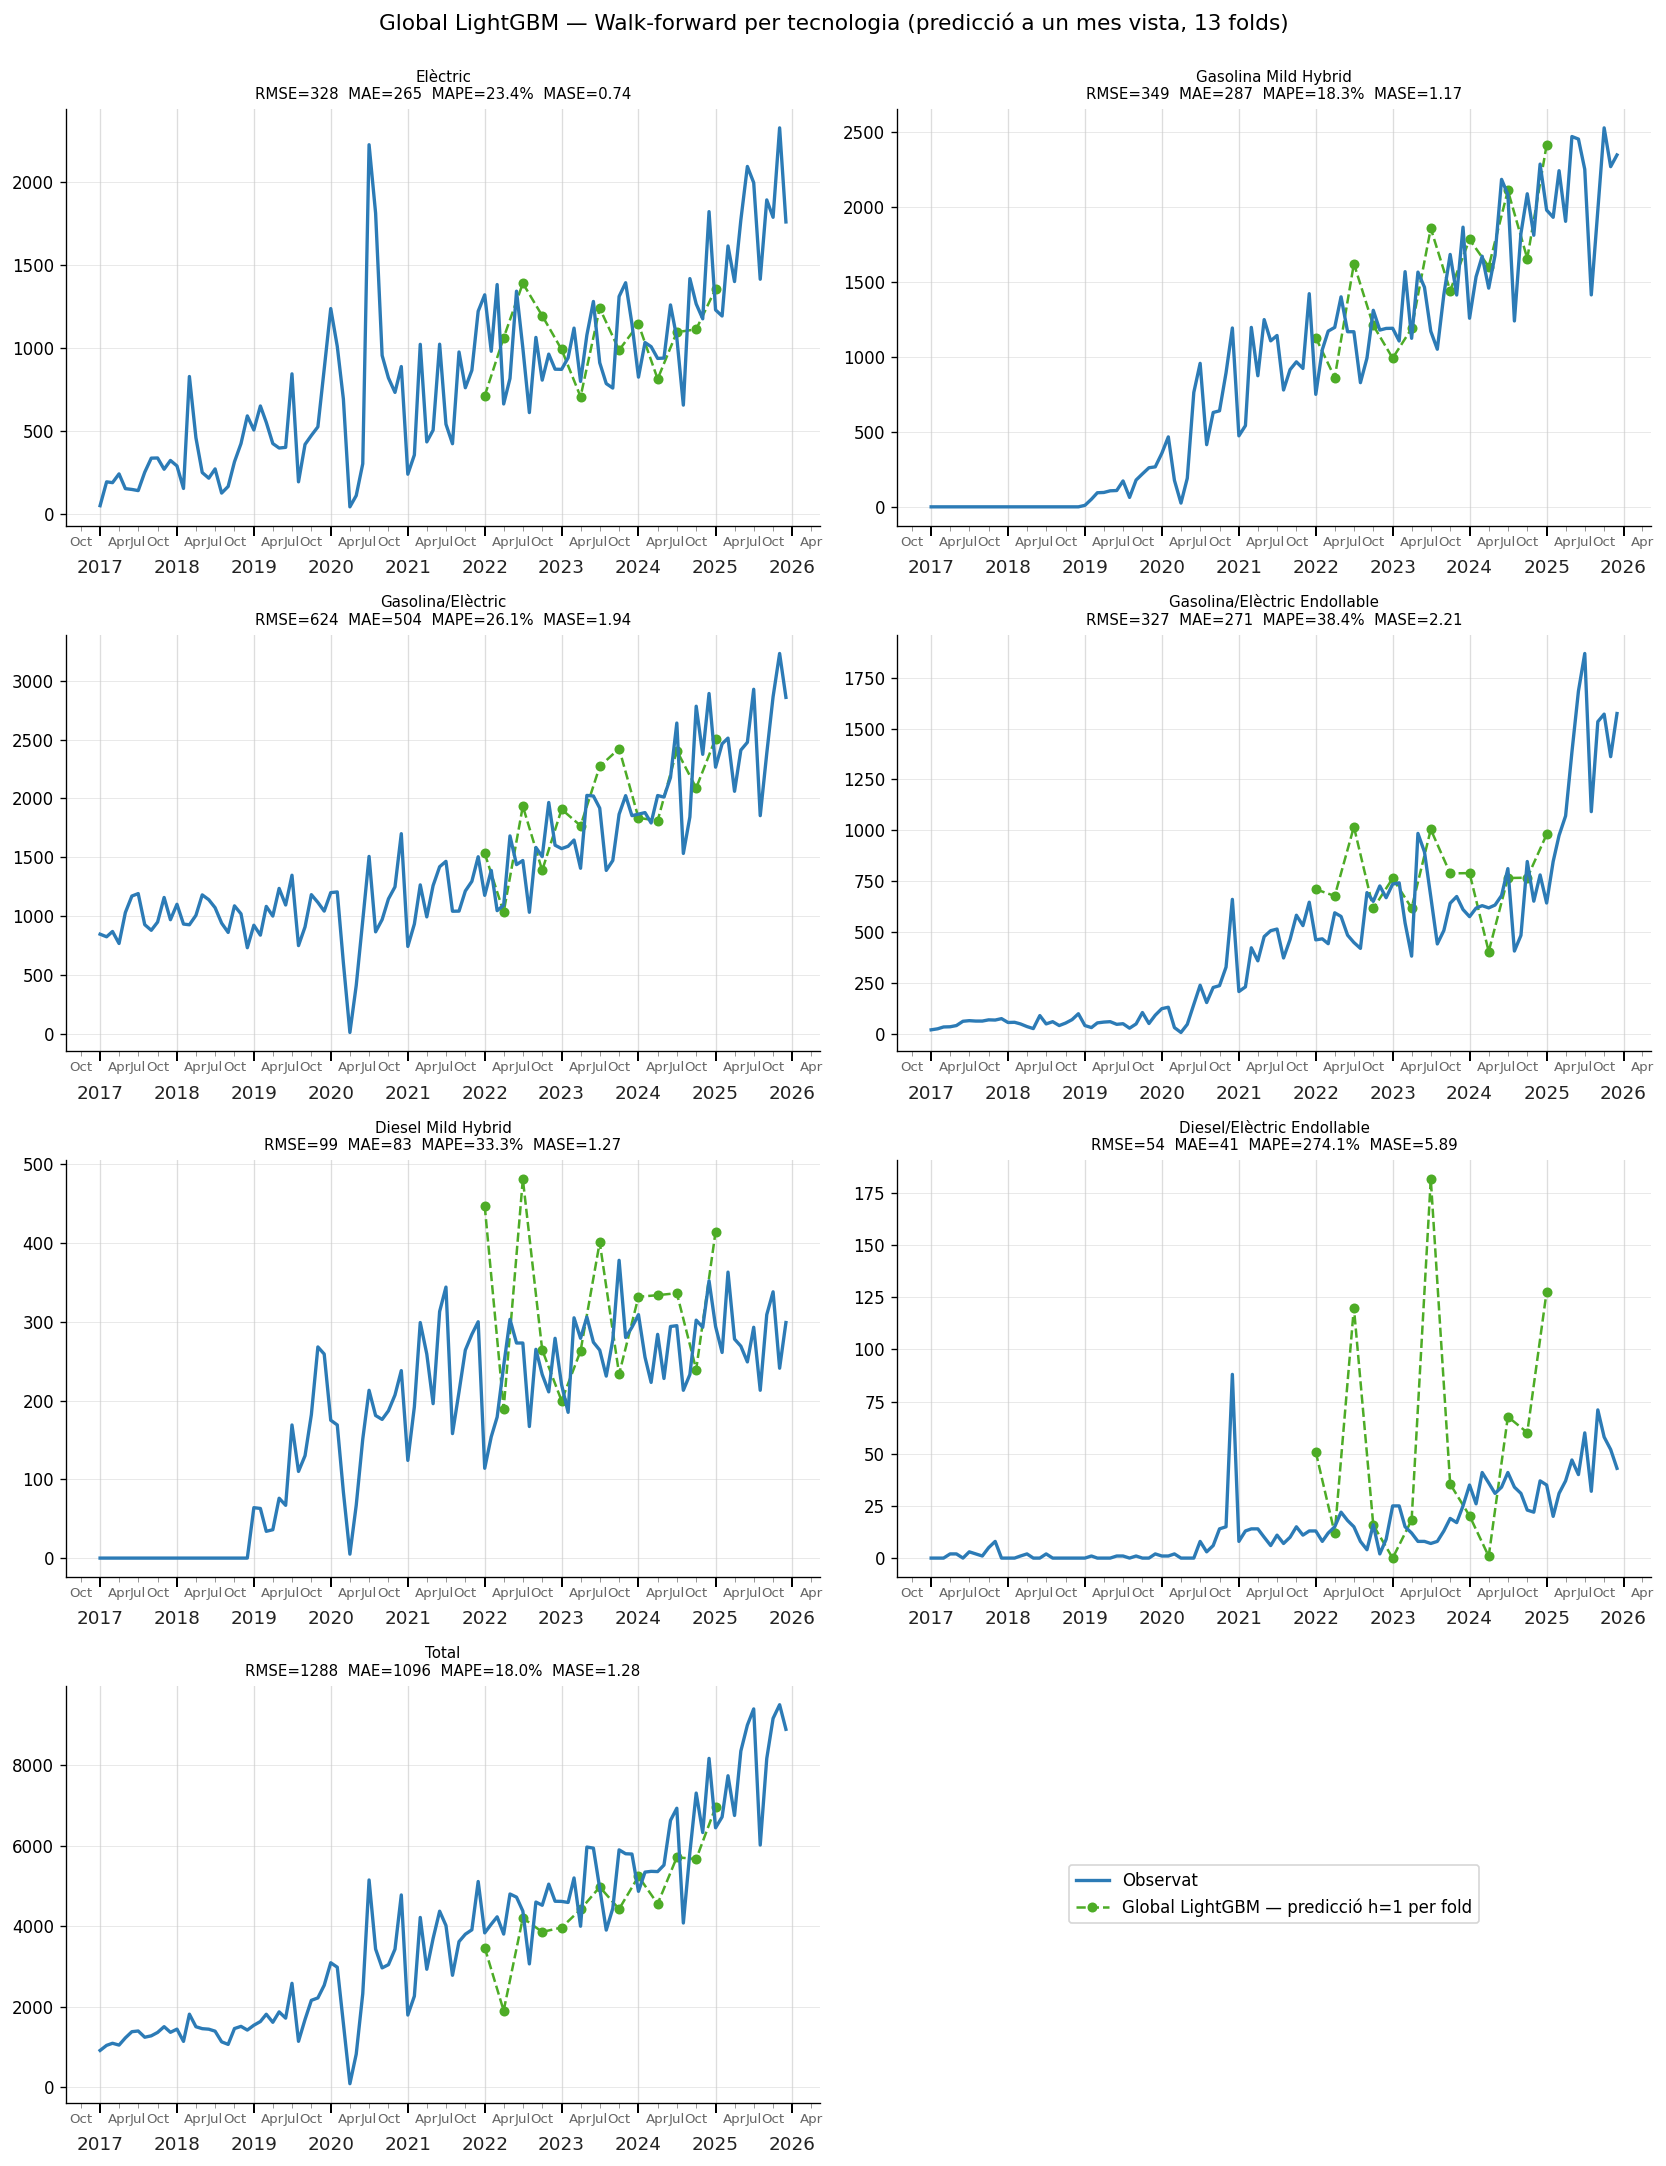

In [18]:
plot_wfv_per_tech(
    pivot_full, df_wfv_forecasts_g, wfv_agg_g,
    tecnologies=TECNOLOGIES, model_name='Global LightGBM',
    save_path=FIGURES_DIR / 'fig_25_global_lgbm_wfv_per_tech.png',
    color_pred='#4dac26',
)
plt.show()

In [19]:
# Guardar resultats Global LightGBM
df_forecasts_g.to_csv(RESULTS_DIR  / 'global_lgbm_forecasts.csv',     index=False)
df_metrics_g.to_csv(RESULTS_DIR    / 'global_lgbm_metrics.csv',       index=False)
df_wfv_metrics_g.to_csv(RESULTS_DIR   / 'global_lgbm_wfv_metrics.csv',   index=False)
df_wfv_forecasts_g.to_csv(RESULTS_DIR / 'global_lgbm_wfv_forecasts.csv', index=False)
print('Guardats: global_lgbm_forecasts.csv, global_lgbm_metrics.csv')
print('          global_lgbm_wfv_metrics.csv, global_lgbm_wfv_forecasts.csv')

Guardats: global_lgbm_forecasts.csv, global_lgbm_metrics.csv
          global_lgbm_wfv_metrics.csv, global_lgbm_wfv_forecasts.csv


---
## Secció 3: Comparació Final

Integrem els dos models nous (Ensemble i Global LightGBM) amb tots els models del benchmark original per determinar quin és el millor globalment. L'avaluació es fa en dues dimensions complementàries:

- **Holdout 2025 (backtest):** una sola realització, útil per veure el comportament en el període real d'interès però amb alta variància.
- **Walk-forward (WFV, 91 folds):** estimació robusta de l'error mig sobre múltiples períodes. És la mesura principal.

In [20]:
# Carregar tots els resultats backtest
metric_files = [f for f in RESULTS_DIR.glob('*_metrics.csv')
                if 'wfv' not in f.name and 'all' not in f.name and 'agg' not in f.name
                and 'global_lgbm' not in f.name and 'ensemble' not in f.name
                and 'ranking' not in f.name]
all_metrics_prev = pd.concat([pd.read_csv(f) for f in metric_files], ignore_index=True)
all_metrics_new  = pd.concat([df_metrics_ens, df_metrics_g], ignore_index=True)
all_metrics_cmp  = pd.concat([all_metrics_prev, all_metrics_new], ignore_index=True)
print(f'Models al benchmark complet: {sorted(all_metrics_cmp["Model"].unique())}')

# Carregar tots els resultats WFV
wfv_files = [f for f in RESULTS_DIR.glob('*_wfv_metrics.csv')
             if 'all' not in f.name and 'agg' not in f.name
             and 'global_lgbm' not in f.name and 'ensemble' not in f.name]
all_wfv_prev = pd.concat([pd.read_csv(f, parse_dates=['fold_start']) for f in wfv_files], ignore_index=True)
all_wfv_new  = pd.concat([df_wfv_metrics_ens, df_wfv_metrics_g], ignore_index=True)
all_wfv_cmp  = pd.concat([all_wfv_prev, all_wfv_new], ignore_index=True).dropna(subset=['MASE'])

Models al benchmark complet: ['AutoSARIMA', 'ETS_Additiu', 'ETS_Multiplicatiu', 'Ensemble', 'GlobalLGBM', 'LSTM', 'LightGBM', 'SeasonalNaive', 'TBATS']


### 3.1 Rànquing global (backtest 2025 vs WFV)

In [21]:
METRICS_4 = ['RMSE', 'MAE', 'MAPE', 'MASE']

hold_global = (all_metrics_cmp.groupby('Model')[METRICS_4].mean().round(2)
               .sort_values('MASE'))
wfv_global  = (all_wfv_cmp.groupby('Model')[METRICS_4].mean().round(2)
               .sort_values('MASE'))

hold_global['Rànquing'] = range(1, len(hold_global) + 1)
wfv_global['Rànquing']  = range(1, len(wfv_global) + 1)

print('=== Rànquing BACKTEST 2025 (1 fold) ===')
display(hold_global)
print('\n=== Rànquing WFV (91 folds) ===')
display(wfv_global)

=== Rànquing BACKTEST 2025 (1 fold) ===


,RMSE,MAE,MAPE,MASE,Rànquing
Model,,,,,
AutoSARIMA,425.25,367.69,19.44,1.49,1
Ensemble,418.51,356.01,19.32,1.52,2
ETS_Additiu,435.56,367.87,19.93,1.55,3
TBATS,418.77,352.45,20.58,1.59,4
LSTM,473.30,405.54,22.70,1.77,5
ETS_Multiplicatiu,588.80,540.98,25.24,1.94,6
SeasonalNaive,645.03,587.54,25.91,2.06,7
LightGBM,687.35,605.91,28.45,2.26,8
GlobalLGBM,642.11,541.22,70.08,3.95,9



=== Rànquing WFV (91 folds) ===


,RMSE,MAE,MAPE,MASE,Rànquing
Model,,,,,
ETS_Additiu,280.87,233.84,23.70,1.01,1
Ensemble,285.25,234.20,23.45,1.01,2
TBATS,331.33,271.51,23.44,1.11,3
AutoSARIMA,306.64,257.11,29.31,1.14,4
LSTM,362.00,300.27,24.47,1.19,5
ETS_Multiplicatiu,383.48,332.19,28.75,1.27,6
SeasonalNaive,390.73,336.64,26.32,1.30,7
LightGBM,457.33,389.93,28.65,1.47,8
GlobalLGBM,438.39,363.84,61.67,2.07,9


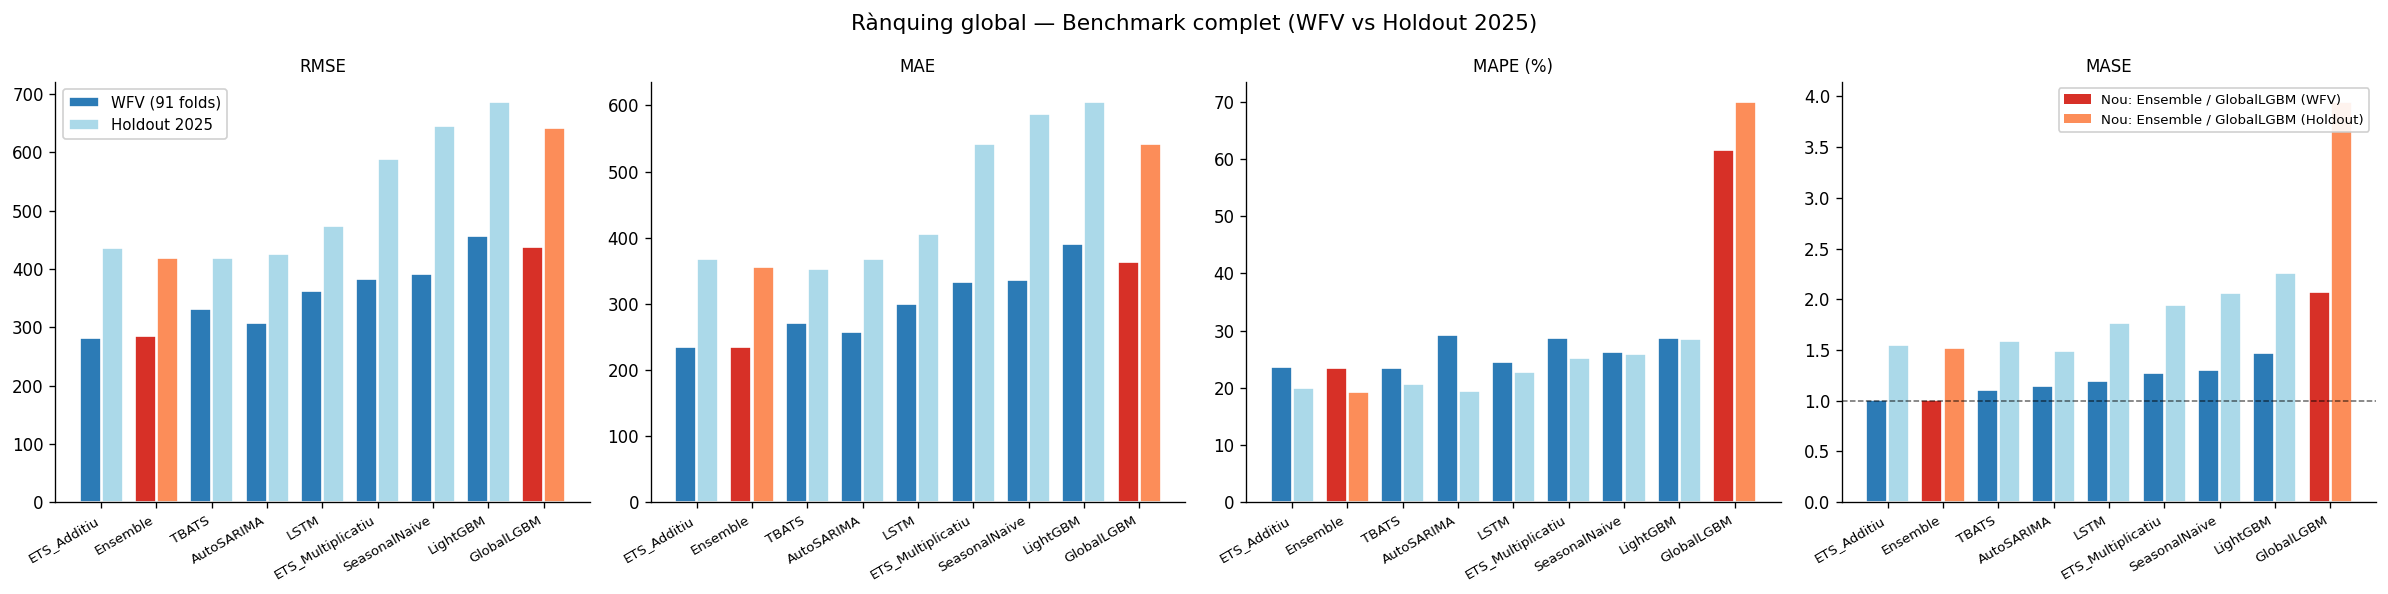

In [22]:
# Bar chart comparatiu: 4 mètriques, 2 avaluacions (backtest vs WFV)
models_wfv_order = wfv_global.index.tolist()
x = np.arange(len(models_wfv_order))
hold_reindexed = hold_global.reindex(models_wfv_order)

# Destacar els models nous
NEW_MODELS = {'Ensemble', 'GlobalLGBM'}

fig, axes = plt.subplots(1, 4, figsize=(20, 5))
for ax, metric in zip(axes, METRICS_4):
    bars_wfv  = wfv_global.loc[models_wfv_order, metric].values
    bars_hold = hold_reindexed[metric].values

    colors_wfv  = ['#d73027' if m in NEW_MODELS else '#2c7bb6' for m in models_wfv_order]
    colors_hold = ['#fc8d59' if m in NEW_MODELS else '#abd9e9' for m in models_wfv_order]

    ax.bar(x - 0.2, bars_wfv,  width=0.38, color=colors_wfv,  label='WFV (91 folds)', edgecolor='white')
    ax.bar(x + 0.2, bars_hold, width=0.38, color=colors_hold, label='Holdout 2025',   edgecolor='white')
    ax.set_xticks(x)
    ax.set_xticklabels(models_wfv_order, rotation=30, ha='right', fontsize=8)
    ax.set_title(f'{metric}' + (' (%)' if metric == 'MAPE' else ''), fontsize=10)
    ax.spines['top'].set_visible(False)
    ax.spines['right'].set_visible(False)
    if metric == 'MASE':
        ax.axhline(1.0, color='black', ls='--', lw=0.9, alpha=0.6)

axes[0].legend(fontsize=9, framealpha=0.9)
# Llegenda per colors de models nous
from matplotlib.patches import Patch
legend_new = [Patch(facecolor='#d73027', label='Nou: Ensemble / GlobalLGBM (WFV)'),
              Patch(facecolor='#fc8d59', label='Nou: Ensemble / GlobalLGBM (Holdout)')]
axes[3].legend(handles=legend_new, fontsize=8, framealpha=0.9, loc='upper right')

plt.suptitle('Rànquing global — Benchmark complet (WFV vs Holdout 2025)', fontsize=13)
plt.tight_layout()
plt.savefig(FIGURES_DIR / 'fig_26_new_model_ranking.png', bbox_inches='tight')
plt.show()

### 3.2 Distribució MASE per fold — Boxplot (WFV)

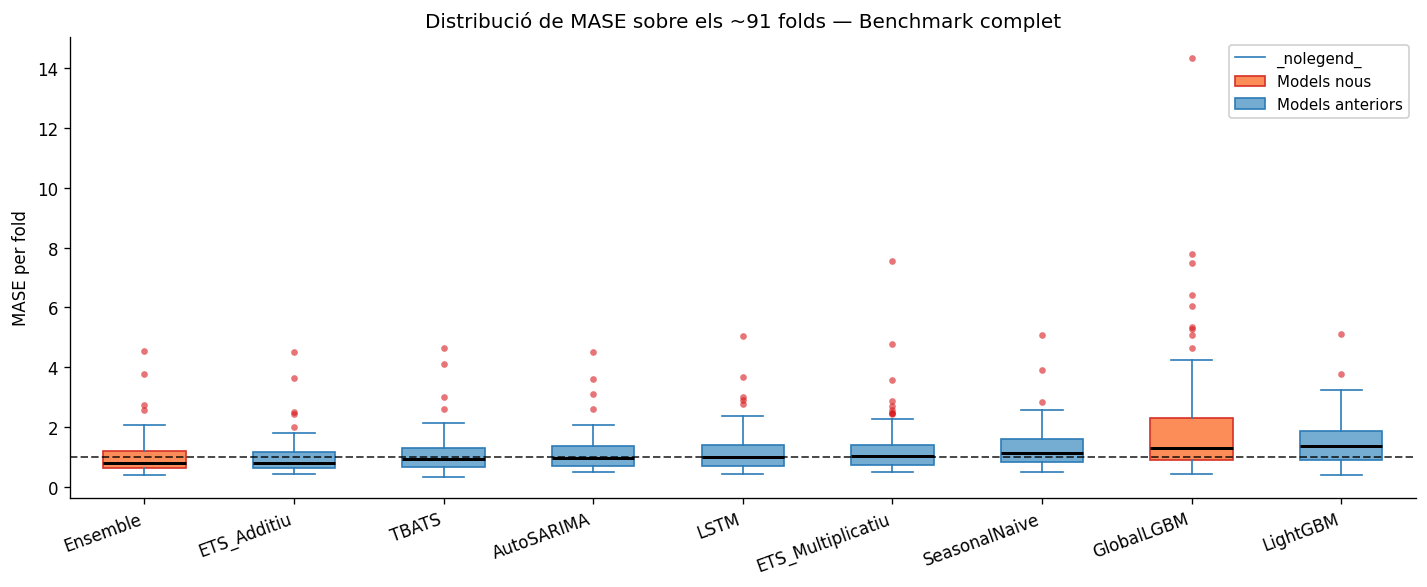

Estadístiques de MASE per model:


,median,mean,std,pct_<1
Model,,,,
Ensemble,0.78,1.01,0.66,63.74
ETS_Additiu,0.81,1.01,0.63,61.54
TBATS,0.93,1.11,0.70,58.24
AutoSARIMA,0.98,1.14,0.66,50.55
LSTM,1.00,1.19,0.74,49.45
ETS_Multiplicatiu,1.02,1.27,0.98,47.25
SeasonalNaive,1.13,1.30,0.71,39.56
GlobalLGBM,1.31,2.07,2.04,30.77
LightGBM,1.38,1.47,0.79,31.87


In [23]:
order_box = all_wfv_cmp.groupby('Model')['MASE'].median().sort_values().index.tolist()
positions  = np.arange(len(order_box))

# Colors: taronja per als models nous
box_colors = ['#fc8d59' if m in NEW_MODELS else '#74add1' for m in order_box]

fig, ax = plt.subplots(figsize=(12, 5))
data = [all_wfv_cmp[all_wfv_cmp['Model'] == m]['MASE'].values for m in order_box]
bp = ax.boxplot(data, positions=positions, widths=0.55, patch_artist=True,
                medianprops=dict(color='black', lw=1.8),
                whiskerprops=dict(color='#2c7bb6'),
                capprops=dict(color='#2c7bb6'),
                flierprops=dict(marker='o', markersize=4, markerfacecolor='#d7191c',
                                markeredgecolor='none', alpha=0.6))
for patch, color in zip(bp['boxes'], box_colors):
    patch.set_facecolor(color)
    patch.set_edgecolor('#2c7bb6' if color == '#74add1' else '#d73027')

ax.axhline(1.0, color='black', ls='--', lw=1.2, alpha=0.7, label='MASE=1 (Seasonal Naive)')
ax.set_xticks(positions)
ax.set_xticklabels(order_box, rotation=20, ha='right')
ax.set_ylabel('MASE per fold')
ax.set_title('Distribució de MASE sobre els ~91 folds — Benchmark complet', fontsize=12)
ax.legend(fontsize=9, framealpha=0.9)
ax.spines['top'].set_visible(False)
ax.spines['right'].set_visible(False)

# Anotació models nous
from matplotlib.patches import Patch
legend_ann = [Patch(facecolor='#fc8d59', edgecolor='#d73027', label='Models nous'),
              Patch(facecolor='#74add1', edgecolor='#2c7bb6', label='Models anteriors')]
ax.legend(handles=[ax.get_lines()[0]] + legend_ann, fontsize=9, framealpha=0.9)

plt.tight_layout()
plt.savefig(FIGURES_DIR / 'fig_27_new_wfv_boxplot.png', bbox_inches='tight')
plt.show()

# Estadístiques de dispersió
disp = (all_wfv_cmp.groupby('Model')['MASE']
        .agg(['median', 'mean', 'std',
              ('pct_<1', lambda x: (x < 1.0).mean() * 100)])
        .round(2).sort_values('median'))
print('Estadístiques de MASE per model:')
display(disp)

### 3.3 Anàlisi per tecnologia (WFV)

In [24]:
wfv_agg_all = (all_wfv_cmp.groupby(['Tecnologia', 'Model'])[METRICS_4]
               .mean().round(2).reset_index())

for tech in TECNOLOGIES:
    sub = (wfv_agg_all[wfv_agg_all['Tecnologia'] == tech]
           .set_index('Model')[METRICS_4].sort_values('MASE'))
    print(f'\n— {tech} —')
    display(sub.style.highlight_min(axis=0, props='font-weight:bold; color:#d73027'))


— Elèctric —


,RMSE,MAE,MAPE,MASE
Model,,,,
ETS_Additiu,306.670000,257.790000,23.840000,0.720000
Ensemble,312.110000,257.260000,22.940000,0.720000
GlobalLGBM,327.950000,264.740000,23.430000,0.740000
LSTM,337.140000,277.930000,23.640000,0.780000
TBATS,337.870000,277.860000,23.550000,0.780000
ETS_Multiplicatiu,348.690000,291.800000,27.340000,0.810000
LightGBM,352.580000,295.100000,24.380000,0.840000
SeasonalNaive,363.660000,300.310000,24.530000,0.850000
AutoSARIMA,450.340000,385.700000,36.730000,1.060000



— Gasolina Mild Hybrid —


,RMSE,MAE,MAPE,MASE
Model,,,,
AutoSARIMA,216.420000,178.240000,11.870000,0.740000
ETS_Multiplicatiu,226.210000,179.990000,11.860000,0.750000
Ensemble,225.240000,184.250000,12.040000,0.760000
ETS_Additiu,235.530000,194.160000,12.690000,0.800000
TBATS,259.350000,207.930000,13.700000,0.860000
LSTM,319.490000,262.990000,15.980000,1.090000
GlobalLGBM,348.740000,286.920000,18.290000,1.170000
SeasonalNaive,377.310000,322.810000,19.300000,1.330000
LightGBM,472.190000,407.500000,24.200000,1.680000



— Gasolina/Elèctric —


...

,RMSE,MAE,MAPE,MASE
Model,,,,
Ensemble,49.770000,40.030000,16.040000,0.610000
TBATS,51.430000,41.750000,16.410000,0.640000
LSTM,51.780000,42.240000,16.430000,0.650000
ETS_Additiu,53.060000,44.520000,18.060000,0.680000
SeasonalNaive,61.550000,47.510000,17.650000,0.730000
ETS_Multiplicatiu,60.880000,49.120000,18.980000,0.750000
LightGBM,61.400000,49.090000,18.040000,0.750000
AutoSARIMA,60.100000,49.860000,19.730000,0.760000
GlobalLGBM,99.400000,83.050000,33.340000,1.270000



— Diesel/Elèctric Endollable —


,RMSE,MAE,MAPE,MASE
Model,,,,
ETS_Additiu,12.150000,9.930000,61.880000,1.440000
Ensemble,12.380000,10.080000,62.700000,1.460000
TBATS,12.740000,10.710000,52.890000,1.540000
LSTM,12.850000,10.930000,55.350000,1.570000
SeasonalNaive,13.920000,11.240000,59.820000,1.630000
AutoSARIMA,15.410000,12.270000,83.880000,1.790000
LightGBM,15.530000,13.090000,63.400000,1.860000
ETS_Multiplicatiu,20.120000,15.400000,79.770000,2.160000
GlobalLGBM,53.770000,41.460000,274.080000,5.890000



— Total —


,RMSE,MAE,MAPE,MASE
Model,,,,
ETS_Additiu,805.580000,676.510000,11.210000,0.790000
Ensemble,832.060000,687.000000,11.580000,0.800000
AutoSARIMA,826.310000,702.870000,11.880000,0.820000
TBATS,1045.520000,854.720000,15.170000,1.000000
LSTM,1121.510000,935.890000,15.920000,1.100000
SeasonalNaive,1204.250000,1077.860000,17.670000,1.260000
GlobalLGBM,1287.750000,1096.110000,18.030000,1.280000
LightGBM,1494.060000,1280.270000,20.860000,1.500000
ETS_Multiplicatiu,1441.040000,1305.840000,22.140000,1.520000


### 3.4 Comparació visual — sèrie Total (tots els models)

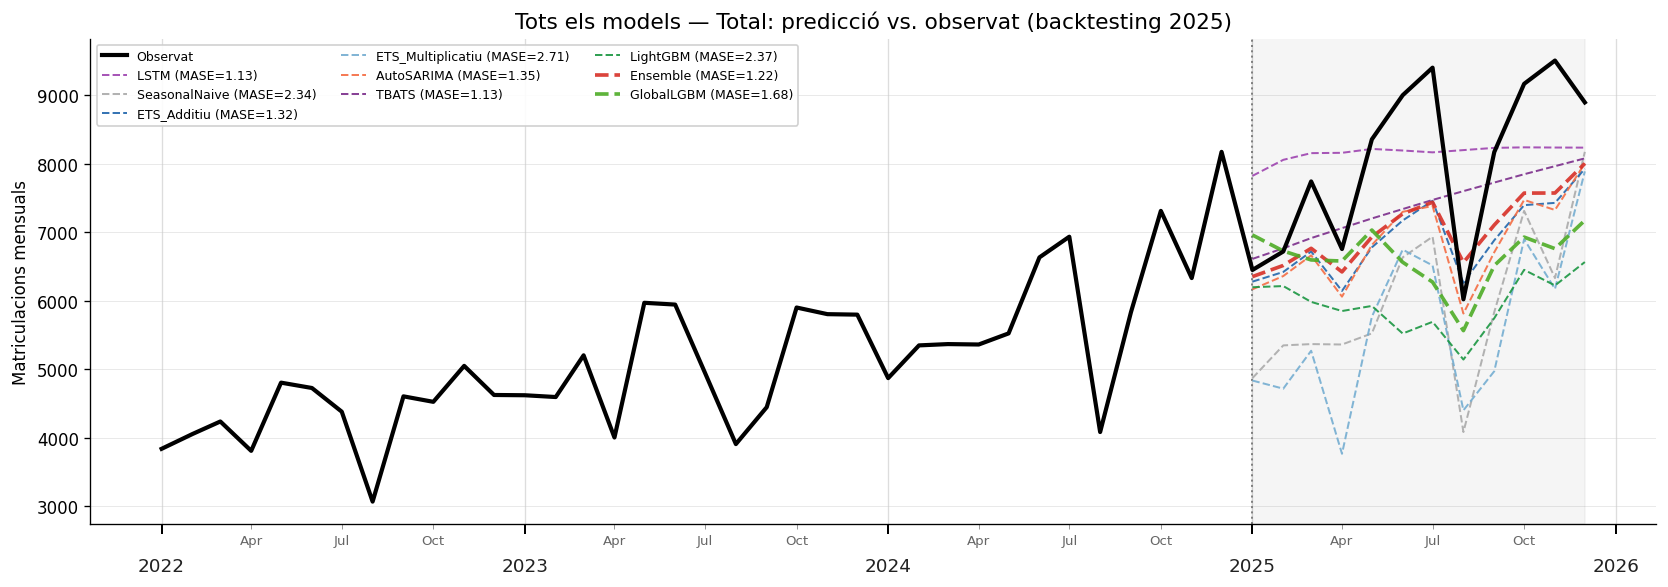

In [25]:
# Carregar tots els forecasts
all_fc_files = [f for f in RESULTS_DIR.glob('*_forecasts.csv')
                if 'wfv' not in f.name and 'all' not in f.name
                and 'global_lgbm' not in f.name and 'ensemble' not in f.name]
all_fc_prev = pd.concat([pd.read_csv(f, parse_dates=['date']) for f in all_fc_files], ignore_index=True)
all_fc_new  = pd.concat([df_forecasts_ens, df_forecasts_g], ignore_index=True)
all_fc_cmp  = pd.concat([all_fc_prev, all_fc_new], ignore_index=True)

palette = {
    'SeasonalNaive':    '#aaaaaa',
    'ETS_Additiu':      '#2166ac',
    'ETS_Multiplicatiu':'#74add1',
    'AutoSARIMA':       '#f46d43',
    'LightGBM':         '#1a9641',
    'LSTM':             '#9e44b0',
    'TBATS':            '#7b2d8b',
    'Ensemble':         '#d73027',
    'GlobalLGBM':       '#4dac26',
}

tech = 'Total'
sub  = all_fc_cmp[all_fc_cmp['Tecnologia'] == tech]

fig, ax = plt.subplots(figsize=(14, 5))
y_tp = pivot_train[tech].iloc[-36:]
y_te = pivot_test[tech]
ax.plot(list(y_tp.index) + list(y_te.index),
        list(y_tp.values) + list(y_te.values),
        color='black', lw=2.5, label='Observat', zorder=10)
ax.axvspan(pivot_test.index[0], pivot_test.index[-1], alpha=0.08, color='gray')
ax.axvline(pivot_test.index[0], color='gray', ls=':', lw=1.2)

for model_name in sub['Model'].unique():
    ms = sub[sub['Model'] == model_name].sort_values('date')
    row = all_metrics_cmp[(all_metrics_cmp['Model'] == model_name) &
                          (all_metrics_cmp['Tecnologia'] == tech)]
    mase_val = row['MASE'].values[0] if len(row) else float('nan')
    lw = 2.2 if model_name in NEW_MODELS else 1.2
    ls = '--'
    ax.plot(ms['date'], ms['predicted'],
            color=palette.get(model_name, '#888888'), lw=lw, ls=ls, alpha=0.9,
            label=f'{model_name} (MASE={mase_val:.2f})')

ax.set_title(f'Tots els models — {tech}: predicció vs. observat (backtesting 2025)', fontsize=13)
ax.set_ylabel('Matriculacions mensuals')
ax.legend(fontsize=7.5, loc='upper left', ncol=3, framealpha=0.9)
format_ts_ax(ax)
plt.tight_layout()
plt.savefig(FIGURES_DIR / 'fig_28_new_comparison_total.png', bbox_inches='tight')
plt.show()

In [26]:
# Guardar rànquings actualitzats
hold_global.reset_index().to_csv(RESULTS_DIR / 'new_model_ranking_holdout.csv', index=False)
wfv_global.reset_index().to_csv(RESULTS_DIR  / 'new_model_ranking_wfv.csv',     index=False)
wfv_agg_all.to_csv(RESULTS_DIR / 'new_wfv_metrics_agg_all.csv', index=False)
print('Guardats: new_model_ranking_holdout.csv, new_model_ranking_wfv.csv, new_wfv_metrics_agg_all.csv')

Guardats: new_model_ranking_holdout.csv, new_model_ranking_wfv.csv, new_wfv_metrics_agg_all.csv


---
## 4. Conclusions

### Quin model és millor?

Els resultats reals del benchmark complet donen dues sorpreses respecte a les prediccions inicials:

**1. L'Ensemble empata amb ETS Additiu, no el supera de forma clara.**

Sota WFV (91 folds), l'Ensemble obté MASE=1.007 i ETS Additiu MASE=1.011. La diferència és de 4 mil·lèsimes: estadísticament negligible i indistingible en qualsevol context pràctic. Tots dos apareixen com 1.01 al rànquing arrodonit. Per tecnologia, l'Ensemble guanya on AutoSARIMA o TBATS són forts (Diesel MH, Gasolina MH) però perd on ETS Additiu domina clarament (Diesel/Elèctric, Elèctric). El resultat net és un empat.

Per qué no millora més? La teoria de la combinació de pronòstics preveu beneficis quan els components fan errors **no correlacionats** i tenen **qualitat similar**. Aquí, els tres models estadístics comparteixen la mateixa estructura bàsica (models paramètrics sobre la mateixa sèrie mensual) i fan errors altament correlats: quan el 2025 creix per sobre del previst, tots tres subestimen alhora. Combinar-los esmorteeix la variança intrafold però no redueix el biaix sistemàtic de subestimació.

**2. El Global LightGBM és pitjor que l'individual, el cross-learning falla.**

El Global LightGBM obté WFV MASE=2.07, clarament pitjor que el LightGBM individual (1.47) i pitjor que el SeasonalNaive (1.30). La causa principal és l'**heterogeneïtat d'escala**: les sèries van des de ~20 unitats/mes (Diesel/Elèctric Endollable) fins a ~6.000 (Total), una diferència de 300×. Amb un sol model global, els arbres de decisió s'orienten cap als residus de les sèries grans (que dominen la funció de pèrdua MSE) i fan prediccions errònies per a les sèries petites. El MAPE de 313% al Diesel/Elèctric Endollable en el backtest confirma que el model ignora pràcticament la dinàmica d'aquesta tecnologia. La variable `tech_id` categòrica no compensa suficientment aquesta distorsió.

**Rànquing final (WFV, mesura principal):**

| Model | WFV MASE real | Posició |
|---|---|---|
| ETS Additiu | **1.01** | **1r** |
| Ensemble | 1.01 (empat) | 2n |
| TBATS | 1.11 | 3r |
| AutoSARIMA | 1.14 | 4t |
| LSTM | 1.19 | 5è |
| ETS Multiplicatiu | 1.27 | 6è |
| SeasonalNaive | 1.30 | referència |
| LightGBM individual | 1.47 | 7è |
| **Global LightGBM** | **2.07** | **Pitjor** |

**Recomanació pràctica:** ETS Additiu és el model a desplegar. Obté el millor (o idèntic) MASE WFV amb molt menys complexitat que l'Ensemble, i és el model que la literatura de M-competitions identifica com el més robust per a sèries mensuals amb estacionalitat anual i N petit. L'Ensemble és una alternativa vàlida si es volen cobrir tecnologies on ETS Additiu falla puntualment (Gasolina MH, Diesel MH), però la millora és mínima.

**Sobre el Global LightGBM:** el resultat negatiu és informatiu. L'enfocament global té sentit teòric però requereix normalitzar les sèries per escala abans de concatenar-les (per exemple, dividir cada sèrie per la seva desviació estàndard i usar MAPE com a funció de pèrdua en lloc de MSE). Sense normalització, les sèries grans dominen l'entrenament i les petites es sacrifiquen. Aquesta és la millora natural a explorar si es vol reactivar el potencial del cross-learning.

**Sobre la subestimació del 2025.** Cap model no elimina el biaix de subestimació del 2025 perquè és un límit informatiu, el creixement de +34% YoY no té precedent a la sèrie i cap model univariant pot anticipar-lo sense dades exògenes sobre polítiques d'incentius, preu dels EVs o expansió de la xarxa de càrrega.